<a href="https://colab.research.google.com/github/jmora420-hue/Ciencia_de_datos/blob/main/Caracterizaci%C3%B3n_datos_censo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, unicodedata, difflib, textwrap
import requests
from bs4 import BeautifulSoup
import time

In [ ]:
!pip install statsmodels
!pip install wquantiles

In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Ciencia de datos/CENSO POBLACIONAL AGOSTO.csv")
df.head()

,cod_dpto,Departamento,cod_mpio,Municipio,fec_paquete,num_paquete,num_ficha,ide_ficha_origen,ide_edificacion,ver_estructura,...,ide_Ug,persug,Capital,marca,estado,Linea_p,replicacion,fec_actualizacion_cns,C,Clasificacion
0,68,SANTANDER,68418,LOS SANTOS,2023-05-03 17:09:24.893,1687,128326,6.841800e+19,0,50118082017,...,6.841870e+26,3,0,0,0,"10,781,693,454",0,2023-11-27 10:33:13.363,4.35,A02
1,68,SANTANDER,68418,LOS SANTOS,2023-05-03 17:09:24.893,1687,128326,6.841800e+19,0,50118082017,...,6.841870e+26,5,0,0,0,"10,781,693,454",0,2023-11-27 10:33:13.363,4.95,C02
2,68,SANTANDER,68418,LOS SANTOS,2023-05-03 17:09:24.893,1687,128326,6.841800e+19,0,50118082017,...,6.841870e+26,5,0,0,0,"10,781,693,454",0,2023-11-27 10:33:13.363,4.95,C02
3,68,SANTANDER,68418,LOS SANTOS,2023-05-03 17:09:24.893,1687,128326,6.841800e+19,0,50118082017,...,6.841870e+26,5,0,0,0,"10,781,693,454",0,2023-11-27 10:33:13.363,4.95,C02
4,68,SANTANDER,68418,LOS SANTOS,2023-05-03 17:09:24.893,1687,128326,6.841800e+19,0,50118082017,...,6.841870e+26,5,0,0,0,"10,781,693,454",0,2023-11-27 10:33:13.363,4.95,C02


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12987 entries, 0 to 12986
Columns: 255 entries, cod_dpto to Clasificacion
dtypes: float64(7), int64(201), object(47)
memory usage: 25.3+ MB


In [ ]:
VEREDAS = {                 # nombre estándar -> patrón (sobre el nombre en mayúscula y sin tildes); atrapa también "PASOCHICO"
    "PASO CHICO": r"\bPASO ?CHICO\b",
    "LOS TERES":  r"\bLOS TERES\b|\bTERES\b",
    "LA LAGUNA":  r"\bLA LAGUNA\b|^LAGUNA$",
}
OBJETIVO = list(VEREDAS)    # veredas de enfoque
TODAS_LAS_VEREDAS = True    # True: limpia e imputa todo el censo (más pesado); False: solo las de OBJETIVO
FINCA_POR = "dir_vivienda"  # columna que identifica la finca (mismo texto = misma finca); si falta, se usa el hogar
PCT_CAP = 0.99              # los valores monetarios se limitan a este percentil (None = no limitar)
MAX_TORTAS = 12             # variables a mostrar en las tortas de resultados imputados
MAX_HOGARES_FINCA = 4       # si una "finca" tiene más hogares que esto, la dirección es genérica y el LOCF se hace solo dentro del hogar

ETQ_BIN = {1: "Sí", 0: "No"}
ETQ_SEXO = {1: "Hombre", 0: "Mujer"}
# Equivalencias código -> significado (diccionario de datos del censo). Lo que no esté aquí sale como "Código n".
CODIGOS = {
    "tip_vivienda": {
        1: "Casa", 2: "Apartamento", 3: "Cuarto(s)", 4: "Vivienda tradicional indígena", 5: "Otro (carpa, contenedor, etc.)"
    },
    "tip_mat_paredes": {
        1: "Bloque, ladrillo, piedra, madera pulida", 2: "Tapia pisada, adobe", 3: "Bahareque",
        4: "Material prefabricado", 5: "Madera burda, tabla, tablón", 6: "Guadua, caña, esterilla", 7: "Zinc, tela, cartón, desecho"
    },
    "tip_mat_pisos": {
        1: "Alfombra o tapete", 2: "Madera pulida, baldosa, vinilo", 3: "Cemento, gravilla",
        4: "Madera burda, tabla, tablón", 5: "Tierra, arena", 6: "Otro material"
    },
    "tip_estrato_energia": {
        0: "Pirata / Contrabando", 1: "Bajo-Bajo", 2: "Bajo", 3: "Medio-Bajo", 4: "Medio", 5: "Medio-Alto", 6: "Alto", 99: "No aplica / No sabe"
    },
    "tip_estrato_acueducto": {
        0: "Pirata / Contrabando", 1: "Bajo-Bajo", 2: "Bajo", 3: "Medio-Bajo", 4: "Medio", 5: "Medio-Alto", 6: "Alto", 99: "No aplica / No sabe"
    },
    "tip_ocupa_vivienda": {
        1: "Propia, totalmente pagada", 2: "Propia, la están pagando", 3: "En arriendo o subarriendo",
        4: "Usufructo o posesión sin título", 5: "Ocupante de hecho / Otra"
    },
    "tip_sanitario": {
        1: "Inodoro conectado a alcantarillado", 2: "Inodoro conectado a pozo séptico", 3: "Inodoro sin conexión",
        4: "Letrina", 5: "Inodoro con descarga directa a fuente de agua", 6: "No tiene"
    },
    "tip_ubi_sanitario": {
        1: "Dentro de la vivienda", 2: "Fuera de la vivienda", 9: "No aplica"
    },
    "tip_uso_sanitario": {
        1: "Uso exclusivo del hogar", 2: "Compartido con otros hogares", 3: "Público", 9: "No aplica"
    },
    "tip_origen_agua": {
        1: "Acueducto público", 2: "Acueducto comunal o veredal", 3: "Pozo con bomba", 4: "Pozo sin bomba / Aljibe",
        5: "Agua lluvia", 6: "Río, quebrada, manantial", 7: "Aguatero, carro tanque", 9: "Otro"
    },
    "tip_uso_agua_beber": {
        1: "Tal como la recogen", 2: "La hierven", 3: "Le echan cloro", 4: "Usan filtro", 5: "Compran agua embotellada", 6: "Otra"
    },
    "tip_elimina_basura": {
        1: "Recolección pública", 2: "La entierran", 3: "La queman", 4: "La tiran a un patio/lote",
        5: "La tiran a río/quebrada", 6: "Otra", 7: "Reciclaje / Compostaje"
    },
    "tip_prepara_alimentos": {
        1: "En un cuarto exclusivo (cocina)", 2: "En el mismo cuarto donde duermen",
        3: "En una sala-comedor", 4: "En un patio, corredor o al aire libre", 5: "No preparan alimentos"
    },
    "tip_uso_cocina": {
        1: "Uso exclusivo del hogar", 2: "Compartida con otros hogares", 3: "No aplica", 9: "Sin información"
    },
    "tip_energia_cocina": {
        1: "Electricidad", 2: "Gas natural (red)", 3: "Gas en cilindro (pipeta)",
        4: "Petróleo, gasolina, kerosén", 5: "Carbón mineral", 6: "Leña, madera o carbón de leña", 7: "Material de desecho", 9: "No aplica / Otra"
    },
    "tip_informante": {
        1: "Jefe o cónyuge", 2: "Otro miembro del hogar", 4: "Informante idóneo / Vecino"
    },
    "tip_documento": {
        1: "Registro civil", 2: "Tarjeta de identidad", 3: "Cédula de ciudadanía", 4: "Cédula de extranjería",
        5: "Pasaporte", 8: "Permiso Especial (PEP)", 9: "No tiene / No sabe"
    },
    "tip_parentesco": {
        1: "Jefe de hogar", 2: "Cónyuge/Compañero(a)", 3: "Hijo(a)", 4: "Nieto(a)", 5: "Padre/Madre",
        6: "Suegro(a)", 7: "Hermano(a)", 8: "Yerno/Nuera", 9: "Abuelo(a)", 10: "Otro pariente",
        11: "Empleado(a) doméstico(a)", 12: "Pariente del empleado(a)", 13: "Trabajador(a)", 14: "Pensionista", 19: "Otro no pariente"
    },
    "tip_estado_civil": {
        1: "Soltero(a)", 2: "Casado(a)", 3: "Unión libre", 4: "Separado(a) / Divorciado(a)", 5: "Viudo(a)"
    },
    "tip_seg_social": {
        0: "No afiliado", 1: "Régimen Contributivo", 2: "Régimen Subsidiado", 3: "Régimen Especial"
    },
    "tip_cuidado_niños": {
        1: "Asiste a guardería o centro de atención", 2: "Con padre / madre en casa", 3: "Con padre / madre en el trabajo",
        4: "Con empleado/a", 5: "Con familiar mayor de 18 años", 8: "Solo en casa", 9: "No aplica"
    },
    "niv_educativo": {
        0: "Ninguno", 1: "Preescolar", 2: "Básica Primaria", 3: "Básica Secundaria", 4: "Media / Bachillerato",
        5: "Técnico / Tecnológico", 6: "Universitario", 7: "Posgrado", 9: "No sabe / No informa"
    },
    "grado_alcanzado": {
        0: "Cero", 1: "Primero", 2: "Segundo", 3: "Tercero", 4: "Cuarto", 5: "Quinto",
        6: "Sexto", 7: "Séptimo", 8: "Octavo", 9: "Noveno", 10: "Décimo", 11: "Undécimo", 13: "Semestres superior", 99: "No aplica"
    },
    "tip_actividad_mes": {
        0: "Menor de edad", 1: "Trabajando", 2: "Buscando trabajo", 3: "Estudiando",
        4: "Oficios del hogar", 5: "Pensionado(a)", 6: "Incapacitado(a) permanente", 7: "Otra actividad", 9: "No informa"
    },
    "tip_empleado": {
        1: "Obrero/empleado particular", 2: "Obrero/empleado gobierno", 3: "Empleado doméstico",
        4: "Cuenta propia (independiente)", 5: "Patrón / Empleador", 6: "Trabajador familiar sin remuneración",
        7: "Trabajador en otra familia sin remuneración", 8: "Jornalero / Peón", 9: "Otro", 10: "No aplica", 99: "No sabe/No informa"
    }
}

def nombre(var):
    """Título legible desde el nombre original de la columna: 'ind_tiene_energia' -> 'Tiene energia'."""
    return re.sub(r"^(ind|tip|num|vlr)_", "", var).replace("_", " ").capitalize()


In [ ]:
def norm_txt(x):
    x = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Za-z0-9 ]", " ", x)).strip().upper()

def estandarizar(nombre_vereda):
    """Las veredas de enfoque toman su nombre estándar aunque estén escritas distinto ('PASOCHICO'); las demás, su nombre normalizado."""
    n = norm_txt(nombre_vereda)
    return next((estandar for estandar, patron in VEREDAS.items() if re.search(patron, n)), n)

col_v = next(c for c in df.columns if str(c).strip().lower() == "nom_vereda")
serie_v = df[col_v].astype(object)
vereda = serie_v.map({u: estandarizar(u) for u in serie_v.dropna().unique()}).astype("string").fillna("SIN VEREDA")

inventario = vereda.value_counts()
print(f"Veredas encontradas en la columna {col_v}: {len(inventario)}")
print(inventario.rename("registros").to_frame())
print("\nVeredas de enfoque (y otros nombres parecidos que NO se incluyeron):")
for v in OBJETIVO:
    pista = v.split()[-1]
    otros = [n for n in inventario.index if pista in n and n != v]
    print(f"  {v}: {inventario.get(v, 0):,} registros" + ("" if v in inventario.index else "  <-- NO ENCONTRADA")
          + f" | otros nombres con '{pista}': {otros}")

sel = vereda.isin(OBJETIVO) | TODAS_LAS_VEREDAS
if not sel.any():
    raise ValueError("No se encontró ninguna vereda de enfoque y TODAS_LAS_VEREDAS = False.")
d = df.loc[sel].reset_index(drop=True)                 # copia: el df original no se modifica
d["vereda_std"] = vereda[sel].values
d["grupo"] = d["vereda_std"].where(d["vereda_std"].isin(OBJETIVO), "OTRAS VEREDAS")
print(f"\nRegistros analizados: {len(d):,} de {len(df):,}")


Veredas encontradas en la columna NOM_VEREDA: 34
                 registros
NOM_VEREDA                
SIN VEREDA            1842
TABACAL               1681
LA FUENTE             1584
EL VERDE               681
ESPINAL ALTO           586
ROSABLANCA             536
LAGUNA BAJA            517
EL POZO                481
LA PURNIA              469
DELICIAS               392
GARBANZAL              302
EL GUAMITO             301
REGADERO BAJO          263
MAJADAL ALTO           262
PASO CHICO             258
EL CARRIZAL            250
PIEDRA DEL RAYO        247
ESPINAL BAJO           247
EL POTRERO             239
REGADERO ALTO          238
LAS LLANADAS           233
LOS TERES              214
MAJADAL BAJO           199
PURNIA NUEVA           133
LOMA DE PURNIA         124
LA LOMA                120
LAGUNA ALTA            119
SAN RAFAEL             115
LA MOJARRA             100
LA PENA                 80
GUAIMARO                78
EL DIAMANTE             49
PURNIA CHIQUITA         42
SALAZA

In [ ]:
nombres = pd.Series([str(c).strip().lower() for c in d.columns])
rep = nombres.groupby(nombres).cumcount()
d.columns = np.where(rep == 0, nombres, nombres + "_" + rep.astype(str))     # minúsculas y sin nombres repetidos

NULOS = ["NULL", "NAN", "NONE", "", "N/A", "NA"]                              # "NULL", vacíos... -> NaN
txt = d.select_dtypes(include=["object", "string"]).columns
d[txt] = d[txt].astype("string").apply(lambda s: s.str.strip())
d[txt] = d[txt].mask(d[txt].apply(lambda s: s.str.upper()).isin(NULOS))

def a_numero(s):
    """'465,000' -> 465000 ; '6,84E+23' -> 6.84e23 ; '4.35' -> 4.35"""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("float64")
    s = s.astype("string").str.strip()
    sci = s.str.contains(r"[eE][+-]?\d+$", na=False)
    s = s.mask(sci, s.str.replace(",", ".", regex=False))
    miles = (~sci) & s.str.contains(r"^-?\d{1,3}(?:,\d{3})+$", na=False)
    s = s.mask(miles, s.str.replace(",", "", regex=False))
    s = s.mask(s.str.contains(",", na=False), s.str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce").astype("float64")

def a_fecha(s):
    """Unifica formatos distintos ('Apr 25 2023 3:02PM', '6/12/19 17:40', '2023-04-25 15:03:13') en una fecha."""
    s = s.astype("string")
    unicos = pd.Series(s.dropna().unique())                    # cada valor distinto se interpreta una sola vez
    try:
        f = pd.to_datetime(unicos, errors="coerce", format="mixed")
    except Exception:
        f = pd.to_datetime(unicos, errors="coerce")
    f = pd.to_datetime(s.map(dict(zip(unicos, f))))
    return f.mask(f.dt.year < 1900)                            # 1753-01-01 = vacío de SQL Server

In [ ]:
def existentes(lista):
    return [c for c in lista if c in d.columns]

ID_NUM = ["num_paquete", "num_ficha", "num_documento", "num_tel_contacto", "num_solicitud", "num_visita",
          "num_hogares_recuento"]                                          # empiezan por num_ pero son identificadores
NUM_COLS = [c for c in d.columns if (c.startswith(("vlr_", "num_", "tot_")) and c not in ID_NUM) or c == "edad_calculada"]
CAT_COLS = [c for c in d.columns if c.startswith(("ind_", "tip_")) or c in ("sexo_persona", "niv_educativo", "grado_alcanzado")]
TODAS = NUM_COLS + CAT_COLS

VLR = [c for c in NUM_COLS if c.startswith("vlr_")]
VLR_GASTOS = [c for c in VLR if c.startswith("vlr_gasto_")]
VLR_INGRESOS = [c for c in VLR if c.startswith("vlr_ingr_") or c == "vlr_otros_ingresos"]
SUBSIDIOS = existentes(["vlr_ingr_fam_accion", "vlr_ingr_col_mayor", "vlr_ingr_otro_subsidio"])
CONTEOS = [c for c in NUM_COLS if c.startswith(("num_", "tot_"))]
DISC = [c for c in CAT_COLS if c.startswith("ind_discap_") and c != "ind_discap_ninguna"]

pos = {c: i for i, c in enumerate(d.columns)}
COLS_HOGAR = [c for c in TODAS if pos[c] < pos.get("ide_persona", 0)]      # columnas antes de ide_persona = datos del hogar
LOCF_FINCA = [c for c in TODAS if re.search(                                 # servicios, agua y riesgos
    r"ind_tiene_(energia|acueducto|alcantarillado|gas|recoleccion|internet)|tip_estrato_|origen_agua|uso_agua|llega|evento", c)]


In [ ]:
d[TODAS] = d[TODAS].apply(a_numero)

def a_binaria(s):
    """Censo: 1 = Sí/Hombre, 2 = No/Mujer  ->  1 y 0. Cualquier otro código (9, 99...) -> NaN."""
    if (s == 0).any():                      # ya venía como 0/1
        return s.where(s.isin([0, 1]))
    return s.map({1: 1.0, 2: 0.0})

BIN_COLS = [c for c in CAT_COLS if c.startswith("ind_") or c == "sexo_persona"]
BIN_COLS += [c for c in CAT_COLS if c not in BIN_COLS and set(d[c].dropna().unique()) == {1.0, 2.0}]
d[BIN_COLS] = d[BIN_COLS].apply(a_binaria)
print("\nVariables binarias (1 = Sí / Hombre, 0 = No / Mujer):", BIN_COLS)

RANGOS = {"edad_calculada": (0, 110), "num_dias_llega": (0, 7), "num_horas_llega": (0, 24),
          "num_mes_ingr_cosecha": (0, 12), "num_sem_buscando": (0, 98), "num_personas_hogar": (1, 40),
          "num_personas_posibles": (0, 40), "num_cuartos_vivienda": (0, 30), "num_cuartos_dormir": (0, 30),
          "num_cuartos_exclusivos": (0, 30), "num_cuartos_unicos_dormir": (0, 30), "num_habita_vivienda": (0, 40)}
for c, (lo, hi) in RANGOS.items():
    if c in d.columns:
        d[c] = d[c].where(d[c].between(lo, hi))
sin_rango = [c for c in NUM_COLS if c not in RANGOS]
d[sin_rango] = d[sin_rango].where(d[sin_rango] >= 0)                      # negativos -> NaN

FECHAS = [c for c in d.columns if c.startswith("fec_")]
d[FECHAS] = d[FECHAS].apply(a_fecha)



Variables binarias (1 = Sí / Hombre, 0 = No / Mujer): ['ind_direccion', 'ind_formato', 'ind_tiene_energia', 'ind_tiene_alcantarillado', 'ind_tiene_gas', 'ind_tiene_recoleccion', 'ind_tiene_acueducto', 'ind_agua_llega_7dias', 'ind_agua_llega_24horas', 'ind_tiene_cocina', 'ind_tiene_nevera', 'ind_tiene_lavadora', 'ind_tiene_pc', 'ind_tiene_internet', 'ind_tiene_moto', 'ind_tiene_tractor', 'ind_tiene_carro', 'ind_tiene_bien_raiz', 'ind_gasto_alimento', 'ind_gasto_transporte', 'ind_gasto_educacion', 'ind_gasto_salud', 'ind_gasto_serv_publicos', 'ind_gasto_celular', 'ind_gasto_arriendo', 'ind_gasto_otros', 'ind_evento_inundacion', 'ind_evento_avalancha', 'ind_evento_terremoto', 'ind_evento_incendio', 'ind_evento_vendaval', 'ind_evento_hundimiento', 'ind_declaracion', 'ind_escaner', 'sexo_persona', 'ind_conyuge_vive_hogar', 'ind_padre_vive_hogar', 'ind_pariente_domestico', 'ind_discap_ver', 'ind_discap_oir', 'ind_discap_hablar', 'ind_discap_moverse', 'ind_discap_bañarse', 'ind_discap_salir'

In [ ]:
# [6] DUPLICADOS: HOGAR POR INFORMANTE, PERSONA POR DOCUMENTO O NOMBRE; LOCF POR FINCA ---
# El informante es el mismo para todos los miembros del hogar, así que identifica el HOGAR (no la persona).
# La PERSONA se identifica por documento o, si falta, por nombre completo + año de nacimiento.
def entero_txt(col):
    return a_numero(d[col]).round().astype("Int64").astype("string")

def unir(columnas):
    """Une columnas de texto en mayúscula y sin tildes: 'jeni' + 'Quezada' -> 'JENI QUEZADA'."""
    texto = pd.Series("", index=d.index, dtype="string")
    for c in columnas:
        if c in d.columns:
            s = d[c].astype("string")
            texto = texto + " " + s.map({u: norm_txt(u) for u in s.dropna().unique()}).fillna("").astype("string")
    return texto.str.replace(r"\s+", " ", regex=True).str.strip()

ficha = entero_txt("num_ficha") + "_" + entero_txt("ide_hogar")
informante = unir(["pri_nom_informante", "seg_nom_informante", "pri_ape_informante", "seg_ape_informante"])
d["hogar_id"] = d["vereda_std"].astype("string") + "|" + informante.mask(informante == "", "ficha " + ficha)

vacio = pd.Series(pd.NA, index=d.index, dtype="string")
doc = d["num_documento"].astype("string").str.replace(r"\D", "", regex=True) if "num_documento" in d.columns else vacio
doc = doc.mask(doc.fillna("").str.strip("0") == "")
anio = d["fec_nacimiento"].astype("string").str.extract(r"(\d{4})")[0] if "fec_nacimiento" in d.columns else vacio
nombre_p = (unir(["pri_nombre", "seg_nombre", "pri_apellido", "seg_apellido"]) + " " + anio.fillna("")).str.strip()
firma = doc.fillna(nombre_p)
firma = firma.mask(firma.fillna("") == "", "persona " + entero_txt("ide_persona"))
d["persona_id"] = d["hogar_id"] + "|" + firma

direccion = unir([FINCA_POR])      # finca = misma dirección (ej. "VEREDA ROSABLANCA FC EL SUSPIRO")
d["finca_id"] = (d["vereda_std"].astype("string") + "|" + direccion).mask(direccion == "", d["hogar_id"])
dist_finca = d.groupby("finca_id")["hogar_id"].nunique()                   # hogares por finca (antes de la protección)
generica = d["finca_id"].map(dist_finca) > MAX_HOGARES_FINCA
d["finca_id"] = d["finca_id"].mask(generica, d["hogar_id"])                # dirección demasiado genérica: se usa el hogar

# Orden cronológico: el último registro de cada persona es el más reciente
ORDEN = [c for c in ["fec_paquete", "fec_fin_encuesta", "fec_ini_encuesta", "fec_actualizacion_cns"] if c in d.columns]
if "num_paquete" in d.columns:
    d["num_paquete"] = a_numero(d["num_paquete"])
    ORDEN.append("num_paquete")
if ORDEN:
    d = d.sort_values(ORDEN, na_position="first", kind="stable")

print("\n=== DUPLICADOS ===")
print(f"Registros (filas): {len(d):,}")
print(f"Fichas distintas (num_ficha + ide_hogar): {ficha.nunique():,}")
print(f"Hogares distintos (por informante): {d['hogar_id'].nunique():,}")
print(f"Personas distintas (por documento o nombre + año de nacimiento): {d['persona_id'].nunique():,}")
print(f"Fincas distintas (por {FINCA_POR}): {len(dist_finca):,}")
print(f"Registros en fincas con más de {MAX_HOGARES_FINCA} hogares (dirección genérica: el LOCF se hace solo dentro del hogar): {int(generica.sum()):,}")
print("Hogares por finca:")
print(dist_finca.value_counts().sort_index().rename("fincas").rename_axis("hogares").to_frame())
print("Registros por persona:")
print(d.groupby("persona_id").size().value_counts().sort_index().rename("personas").rename_axis("registros").to_frame())
print("Último registro = el más reciente según:", ORDEN if ORDEN else "orden original del archivo")

# LOCF: servicios, agua y riesgos faltantes se completan con la última observación de la MISMA FINCA
# (registros ordenados por fecha). Luego se conserva el registro más reciente de cada persona.
ultimo = ~d["persona_id"].duplicated(keep="last")
antes = d.loc[ultimo, LOCF_FINCA].isna().sum()
d[LOCF_FINCA] = d.groupby("finca_id")[LOCF_FINCA].ffill()
locf = pd.DataFrame({"nulos_antes": antes, "completados_con_LOCF": antes - d.loc[ultimo, LOCF_FINCA].isna().sum()})
print("\n=== LOCF (servicios, agua y riesgos, dentro de la misma finca): nulos completados ===")
print(locf[locf.completados_con_LOCF > 0] if (locf.completados_con_LOCF > 0).any() else "Ninguno (no había registros anteriores de la finca con el dato)")

d = d.loc[ultimo].copy()                                                   # se conserva solo el último registro
print(f"Registros después de quedarnos con el último de cada persona: {len(d):,}")
d["n_personas_obs"] = d.groupby("hogar_id")["hogar_id"].transform("size")

# Dato de HOGAR faltante en una persona pero presente en otra del mismo hogar -> se copia el más reciente
d[COLS_HOGAR] = d[COLS_HOGAR].fillna(d.groupby("hogar_id")[COLS_HOGAR].transform("last"))

if PCT_CAP:                                                                # valores monetarios extremos
    tope = d[VLR].where(d[VLR] > 0).quantile(PCT_CAP)                      # percentil de los valores positivos
    d[VLR] = d[VLR].clip(upper=tope, axis=1)



=== DUPLICADOS ===
Registros (filas): 12,987
Fichas distintas (num_ficha + ide_hogar): 4,510
Hogares distintos (por informante): 4,485
Personas distintas (por documento o nombre + año de nacimiento): 12,987
Fincas distintas (por dir_vivienda): 3,101
Registros en fincas con más de 4 hogares (dirección genérica: el LOCF se hace solo dentro del hogar): 1,340
Hogares por finca:
         fincas
hogares        
1          2363
2           491
3           151
4            45
5            18
6            10
7             5
8             5
9             1
10            1
11            2
15            1
16            1
20            1
22            1
26            2
29            1
34            1
67            1
Registros por persona:
           personas
registros          
1             12987
Último registro = el más reciente según: ['fec_paquete', 'fec_fin_encuesta', 'fec_ini_encuesta', 'fec_actualizacion_cns', 'num_paquete']

=== LOCF (servicios, agua y riesgos, dentro de la misma finca): n

In [ ]:
nulos = pd.DataFrame({"n_nulos": d[TODAS].isna().sum(), "pct_nulos": d[TODAS].isna().mean() * 100})
print("\n=== NULOS ANTES DE IMPUTAR (no se elimina ninguna columna) ===")
print(nulos[nulos.n_nulos > 0].sort_values("n_nulos", ascending=False).round(1))

# Pares indicador (1/0) -> valor monetario: ind_gasto_alimento <-> vlr_gasto_alimento, ind_ingr_salario <-> vlr_ingr_salario...
PARES = [(c.replace("vlr_", "ind_", 1), c) for c in VLR if c.replace("vlr_", "ind_", 1) in d.columns]

def g(c):   # columna, o serie vacía si no existe (las reglas no fallan por columnas ausentes)
    return d[c] if c in d.columns else pd.Series(np.nan, index=d.index)

conflictos = pd.Series({
    "indicador = No pero valor > 0": sum(((d[i] == 0) & (d[v] > 0)).sum() for i, v in PARES),
    "indicador = Sí pero valor = 0": sum(((d[i] == 1) & (d[v] == 0)).sum() for i, v in PARES),
    "'ninguna discapacidad' = Sí pero hay una específica":
        int(((g("ind_discap_ninguna") == 1) & (d[DISC] == 1).any(axis=1)).sum()) if DISC else 0,
    "sin energía pero con estrato de energía": int(((g("ind_tiene_energia") == 0) & g("tip_estrato_energia").between(0, 6)).sum()),
    "sin acueducto pero con estrato de acueducto": int(((g("ind_tiene_acueducto") == 0) & g("tip_estrato_acueducto").between(0, 6)).sum()),
}, name="n_inconsistencias")
print("\n=== INCONSISTENCIAS ENTRE COLUMNAS RELACIONADAS (si son altas, la regla no es confiable) ===")
print(conflictos)



=== NULOS ANTES DE IMPUTAR (no se elimina ninguna columna) ===
                          n_nulos  pct_nulos
num_mes_ingr_cosecha        12949       99.7
num_dias_llega              12891       99.3
ind_ingr_cosecha            12737       98.1
ind_fue_atendido_salud      12576       96.8
ind_acudio_salud            12434       95.7
ind_ingr_honorarios         12355       95.1
num_horas_llega             12092       93.1
ind_recibe_comida           11939       91.9
ind_agua_llega_24horas      11650       89.7
ind_agua_llega_7dias        11650       89.7
ind_ingr_salario            11549       88.9
num_sem_buscando            10582       81.5
ind_esta_embarazada          8027       61.8
ind_conyuge_vive_hogar       7764       59.8
ind_tuvo_hijos               7330       56.4
ind_ingr_estado              3405       26.2
ind_fondo_pensiones          3017       23.2
ind_ingr_pension             1645       12.7
ind_ingr_arriendos           1644       12.7
ind_ingr_remesa_pais         1644   

In [ ]:
log = []

def rellenar(col, cond, valor, regla):
    if col not in d.columns:
        return
    m = d[col].isna() & cond.fillna(False)
    if m.any():
        d.loc[m, col] = valor if np.isscalar(valor) else valor[m]
        log.append({"regla": regla, "columna": col, "nulos_resueltos": int(m.sum())})

for ind, vlr in PARES:                                               # indicador <-> valor
    rellenar(ind, d[vlr] > 0, 1, "valor > 0  =>  indicador = Sí")
    rellenar(ind, d[vlr] == 0, 0, "valor = 0  =>  indicador = No")
    rellenar(vlr, d[ind] == 0, 0, "indicador = No  =>  valor = 0")

if SUBSIDIOS:                                                        # subsidios del Estado
    rellenar("ind_ingr_estado", d[SUBSIDIOS].sum(axis=1, min_count=1) > 0, 1, "algún subsidio > 0  =>  Sí")
    rellenar("ind_ingr_estado", (d[SUBSIDIOS] == 0).all(axis=1), 0, "todos los subsidios = 0  =>  No")
    for v in SUBSIDIOS:
        rellenar(v, g("ind_ingr_estado") == 0, 0, "ingreso del Estado = No  =>  subsidio = 0")

if VLR_GASTOS:                                                       # gasto total = suma de componentes
    suma = d[VLR_GASTOS].sum(axis=1, min_count=len(VLR_GASTOS))
    rellenar("vlr_total_gastos", suma.notna(), suma, "total gastos = suma de componentes")

if DISC:                                                             # discapacidad
    rellenar("ind_discap_ninguna", (d[DISC] == 1).any(axis=1), 0, "alguna discapacidad = Sí  =>  'ninguna' = No")
    rellenar("ind_discap_ninguna", (d[DISC] == 0).all(axis=1), 1, "todas = No  =>  'ninguna' = Sí")
    for c in DISC:
        rellenar(c, g("ind_discap_ninguna") == 1, 0, "'ninguna' = Sí  =>  discapacidad específica = No")

for ind, est in [("ind_tiene_energia", "tip_estrato_energia"), ("ind_tiene_acueducto", "tip_estrato_acueducto")]:
    rellenar(ind, g(est).between(0, 6), 1, "tiene estrato (0 = conexión pirata, 1-6)  =>  tiene servicio")
    rellenar(ind, g(est) == 99, 0, "estrato = 99  =>  no tiene servicio")
    rellenar(est, g(ind) == 0, 99, "no tiene servicio  =>  estrato = 99")

rellenar("ind_agua_llega_7dias", g("num_dias_llega") == 7, 1, "días de agua = 7  =>  llega 7 días")
rellenar("ind_agua_llega_7dias", g("num_dias_llega").between(0, 6), 0, "días de agua < 7  =>  No")
rellenar("num_dias_llega", g("ind_agua_llega_7dias") == 1, 7, "llega 7 días  =>  días = 7")
rellenar("ind_agua_llega_24horas", g("num_horas_llega") == 24, 1, "horas = 24  =>  llega 24 h")
rellenar("ind_agua_llega_24horas", g("num_horas_llega").between(0, 23), 0, "horas < 24  =>  No")
rellenar("num_horas_llega", g("ind_agua_llega_24horas") == 1, 24, "llega 24 h  =>  horas = 24")

edad, hombre = g("edad_calculada"), g("sexo_persona") == 1          # reglas por edad / sexo
rellenar("ind_esta_embarazada", hombre | (edad < 10) | (edad > 60), 0, "hombre o edad fuera de 10-60  =>  No")
rellenar("ind_tuvo_hijos", edad < 10, 0, "menor de 10  =>  No")
rellenar("ind_leer_escribir", edad < 5, 0, "menor de 5  =>  No")
rellenar("num_sem_buscando", edad < 15, 0, "menor de 15  =>  0 semanas buscando trabajo")

rellenar("ind_acudio_salud", g("ind_enfermo_30") == 0, 0, "no se enfermó  =>  no acudió")     # cadena de salud
rellenar("ind_fue_atendido_salud", g("ind_acudio_salud") == 0, 0, "no acudió  =>  no fue atendido")
rellenar("num_mes_ingr_cosecha", g("ind_ingr_cosecha") == 0, 0, "sin ingreso de cosecha  =>  0 meses")
rellenar("num_personas_hogar", d["n_personas_obs"].notna(), d["n_personas_obs"], "personas del hogar = personas del hogar en el censo")

resumen = pd.DataFrame(log)
print("\n=== NULOS RESUELTOS POR RELACIÓN ENTRE COLUMNAS ===")
print(resumen.sort_values("nulos_resueltos", ascending=False).to_string(index=False) if len(resumen) else "Ninguno")



=== NULOS RESUELTOS POR RELACIÓN ENTRE COLUMNAS ===
                                      regla                  columna  nulos_resueltos
        sin ingreso de cosecha  =>  0 meses     num_mes_ingr_cosecha            12949
              valor = 0  =>  indicador = No         ind_ingr_cosecha            12737
             no acudió  =>  no fue atendido   ind_fue_atendido_salud            12566
               no se enfermó  =>  no acudió         ind_acudio_salud            12434
              valor = 0  =>  indicador = No      ind_ingr_honorarios            12355
              valor = 0  =>  indicador = No         ind_ingr_salario            11549
       hombre o edad fuera de 10-60  =>  No      ind_esta_embarazada             7991
            todos los subsidios = 0  =>  No          ind_ingr_estado             3405
menor de 15  =>  0 semanas buscando trabajo         num_sem_buscando             3147
                        menor de 10  =>  No           ind_tuvo_hijos             1888
 

In [ ]:
#[9] IMPUTACIÓN: media / mediana / moda, calculadas por vereda (todo vectorizado) ----
registros = []

# Numéricas: media si la distribución es simétrica, mediana (cuantil 50%) si es asimétrica.
# Una sola transform por método para todas las columnas a la vez.
nulos_num = d[NUM_COLS].isna().sum()
num_imp = nulos_num[(nulos_num > 0) & (nulos_num < len(d))].index.tolist()
asim = d[num_imp].skew()
ceros = (d[num_imp] == 0).mean()
simetrica = asim.abs() < 0.5
for metodo, funcion, cols in [("media", "mean", simetrica[simetrica].index.tolist()),
                              ("mediana", "median", simetrica[~simetrica].index.tolist())]:
    if cols:
        global_ = d[cols].agg(funcion)                                           # respaldo: todas las veredas juntas
        d[cols] = d[cols].fillna(d.groupby("vereda_std")[cols].transform(funcion)).fillna(global_)
        registros += [{"variable": c, "nulos": int(nulos_num[c]), "metodo": metodo, "valor_global": global_[c],
                       "motivo": (f"distribución simétrica (asimetría {asim[c]:.2f})" if metodo == "media" else
                                  f"distribución asimétrica (asimetría {asim[c]:.2f}, {ceros[c]:.0%} ceros): "
                                  f"el cuantil 50% no lo distorsionan los extremos")} for c in cols]
conteos_imp = [c for c in num_imp if c in CONTEOS]
d[conteos_imp] = d[conteos_imp].round()                                          # 2.4 cuartos no tiene sentido

# Categóricas y binarias: moda. La moda de cada vereda sale de contar (vereda, categoría) y tomar el máximo.
nulos_cat = d[CAT_COLS].isna().sum()
cat_imp = nulos_cat[(nulos_cat > 0) & (nulos_cat < len(d))].index.tolist()
moda_global = d[cat_imp].mode().iloc[0] if cat_imp else pd.Series(dtype=float)
for c in cat_imp:
    cuentas = d.groupby(["vereda_std", c]).size()
    moda_vereda = cuentas.groupby(level=0).idxmax().map(lambda t: t[1])
    d[c] = d[c].fillna(d["vereda_std"].map(moda_vereda)).fillna(moda_global[c])
    registros.append({"variable": c, "nulos": int(nulos_cat[c]), "metodo": "moda", "valor_global": moda_global[c],
                      "motivo": "binaria: categoría más frecuente" if c in BIN_COLS else "categórica: categoría más frecuente"})

sin_datos = d[TODAS].columns[d[TODAS].isna().all()].tolist()                     # columnas vacías: se conservan
registros += [{"variable": c, "nulos": len(d), "metodo": "sin imputar", "valor_global": np.nan,
               "motivo": "no hay ningún dato en ninguna vereda"} for c in sin_datos]

tabla_imp = pd.DataFrame(registros).sort_values("nulos", ascending=False)
print("\n=== VARIABLES IMPUTADAS: MÉTODO Y MOTIVO (estadística calculada por vereda; si no hay, de todas juntas) ===")
print(tabla_imp.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

d[CAT_COLS] = d[CAT_COLS].round().astype("Int64")                                # 1/0 y códigos como enteros



=== VARIABLES IMPUTADAS: MÉTODO Y MOTIVO (estadística calculada por vereda; si no hay, de todas juntas) ===
              variable  nulos  metodo  valor_global                                                                                              motivo
     ind_recibe_comida  11939    moda          1.00                                                                    binaria: categoría más frecuente
        num_dias_llega  11651 mediana          7.00 distribución asimétrica (asimetría -3.84, 0% ceros): el cuantil 50% no lo distorsionan los extremos
  ind_agua_llega_7dias  11650    moda          1.00                                                                    binaria: categoría más frecuente
ind_agua_llega_24horas  11650    moda          0.00                                                                    binaria: categoría más frecuente
       num_horas_llega  11650 mediana          6.00  distribución asimétrica (asimetría 0.54, 1% ceros): el cuantil 50% no lo disto

In [ ]:
d["ingreso_persona"] = d[VLR_INGRESOS].sum(axis=1)
d["ingreso_hogar"] = d.groupby("hogar_id")["ingreso_persona"].transform("sum")
d["ingreso_pc"] = d["ingreso_hogar"] / d["n_personas_obs"]
if "vlr_total_gastos" in d.columns:
    d["gasto_pc"] = d["vlr_total_gastos"] / d["n_personas_obs"]
d["grupo_edad"] = pd.cut(d["edad_calculada"], bins=list(range(0, 85, 5)) + [200], right=False,
                         labels=[f"{i}-{i+4}" for i in range(0, 80, 5)] + ["80+"])
d["sexo"] = d["sexo_persona"].map(ETQ_SEXO)
if DISC:
    d["alguna_discapacidad"] = (d[DISC] == 1).any(axis=1).astype(int)

df_limpio = d                                                       # 1 fila = 1 persona (último registro)
hogares = df_limpio.drop_duplicates("hogar_id", keep="last").copy() # 1 fila = 1 hogar
mayores15 = df_limpio[df_limpio["edad_calculada"] >= 15]
VER = [v for v in OBJETIVO + ["OTRAS VEREDAS"] if v in df_limpio["grupo"].unique()]
print(f"\ndf_limpio: {len(df_limpio):,} personas | hogares: {len(hogares):,} | "
      f"nulos restantes: {int(df_limpio[TODAS].isna().sum().sum())}")



df_limpio: 12,987 personas | hogares: 4,485 | nulos restantes: 0


In [ ]:
def pct(cond, grupo):
    return cond.fillna(False).astype("float64").groupby(grupo).mean() * 100

def conteo(base, var):
    """Cuenta categorías con etiquetas que se entienden: Sí/No, Hombre/Mujer, diccionario o 'Código n'."""
    s = base[var].dropna()
    binaria = var in BIN_COLS or var == "alguna_discapacidad"
    etq = ETQ_SEXO if var == "sexo_persona" else ETQ_BIN if binaria else CODIGOS.get(var, {})
    if var in CAT_COLS or var == "alguna_discapacidad":
        v = s.value_counts().sort_index(ascending=False) if binaria else s.value_counts()
        v.index = [etq.get(i, f"Código {i}") for i in v.index]
    elif s.nunique() <= 6:
        v = s.value_counts().sort_index()
        v.index = [f"{i:,.0f}" for i in v.index]
    else:                                                  # numérica continua: ceros aparte + cuartiles de lo demás
        ceros_ = pd.Series({"0": int((s == 0).sum())}) if (s == 0).any() else pd.Series(dtype=int)
        q = pd.qcut(s[s != 0], 4, duplicates="drop").value_counts().sort_index()
        q.index = [f"{i.left:,.0f} a {i.right:,.0f}" for i in q.index]
        v = pd.concat([ceros_, q])
    if len(v) > 6:
        v = pd.concat([v.iloc[:6], pd.Series({"Otros": v.iloc[6:].sum()})])
    return v

def torta(ax, serie, titulo, con_n=True, unidad="personas"):
    serie = serie[serie > 0]
    if serie.empty:
        ax.set_title(f"{titulo}\n(sin datos)", fontsize=10)
        ax.axis("off")
        return
    total = serie.sum()
    ax.pie(serie.values, colors=plt.get_cmap("Set2").colors[:len(serie)], startangle=90, counterclock=False,
           autopct=lambda p: f"{p:.0f}%" if p >= 5 else "", pctdistance=0.7,
           wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 9})
    leyenda = [textwrap.fill(f"{i}: {v:,.0f} ({v / total:.0%})" if con_n else f"{i} ({v / total:.0%})", 34) for i, v in serie.items()]
    ax.legend(leyenda, loc="upper center", bbox_to_anchor=(0.5, 0.02), fontsize=8, frameon=False)
    ax.set_title(f"{titulo}\n(n = {total:,.0f} {unidad})" if con_n else titulo, fontsize=10)

def tortas(conteos, titulos, ncols=3, suptitulo=None, unidades=None, **kw):
    nrows = int(np.ceil(len(conteos) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 5.2 * nrows), squeeze=False, layout="constrained")
    for i, (ax, s, t) in enumerate(zip(axes.ravel(), conteos, titulos)):
        torta(ax, s, t, **({"unidad": unidades[i]} if unidades else {}), **kw)
    for ax in axes.ravel()[len(conteos):]:
        ax.axis("off")
    if suptitulo:
        fig.suptitle(suptitulo, fontsize=14)
    plt.show()

def tortas_por_vereda(base, variables, suptitulo, unidad="personas", por_figura=3):
    """Una fila por variable, una torta por grupo (las 3 veredas + OTRAS VEREDAS)."""
    for i in range(0, len(variables), por_figura):
        bloque = variables[i:i + por_figura]
        tortas([conteo(base[base["grupo"] == v], var) for var in bloque for v in VER],
               [f"{nombre(var)}\n{v}" for var in bloque for v in VER],
               ncols=len(VER), suptitulo=suptitulo, unidad=unidad)


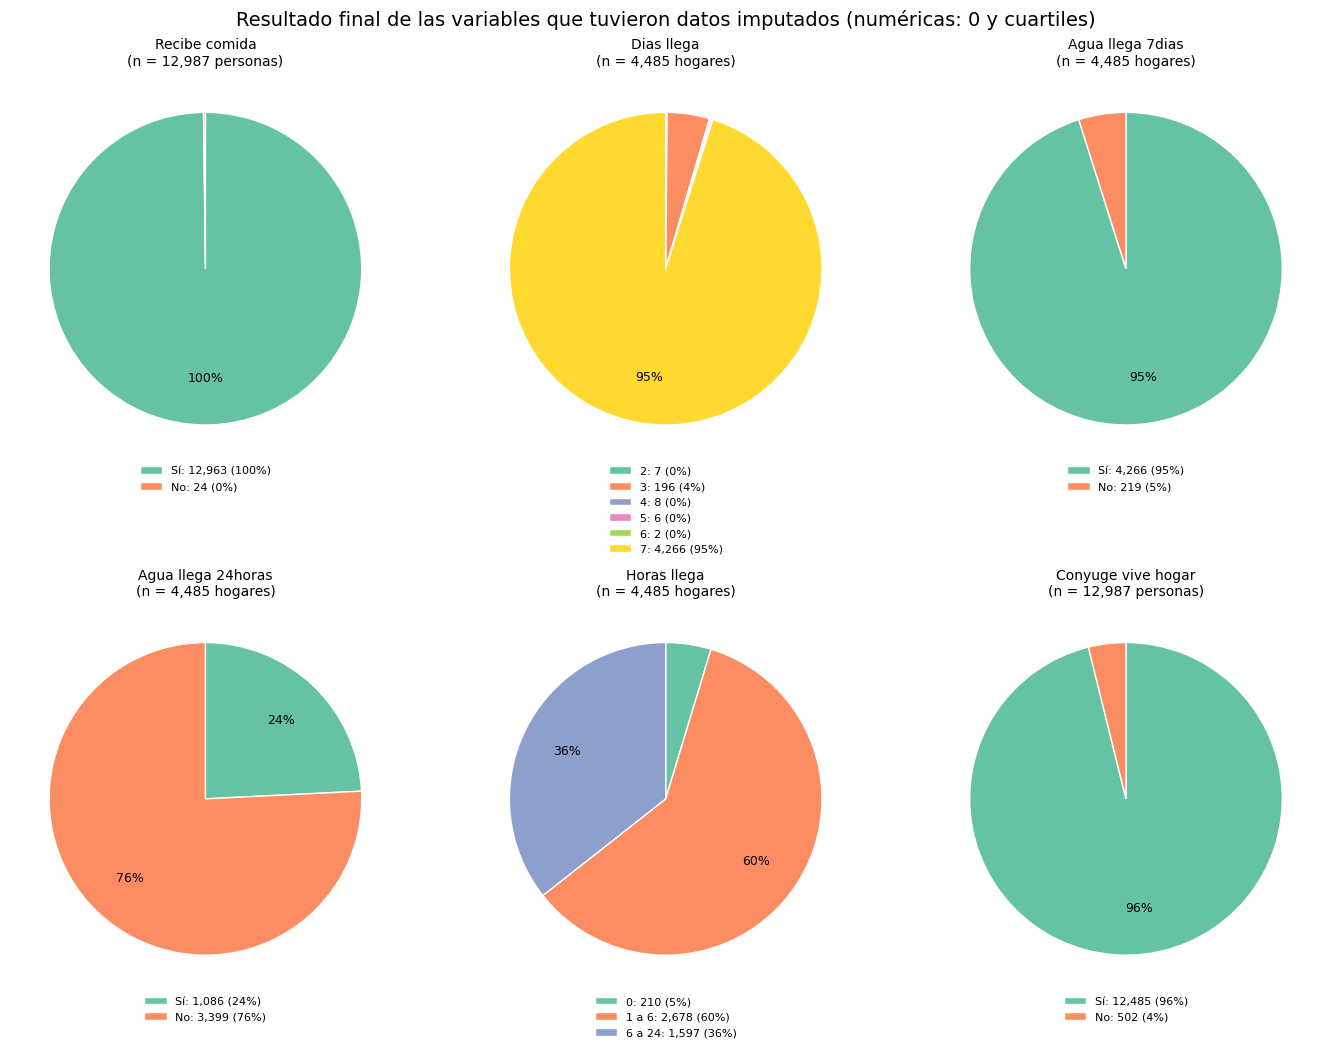

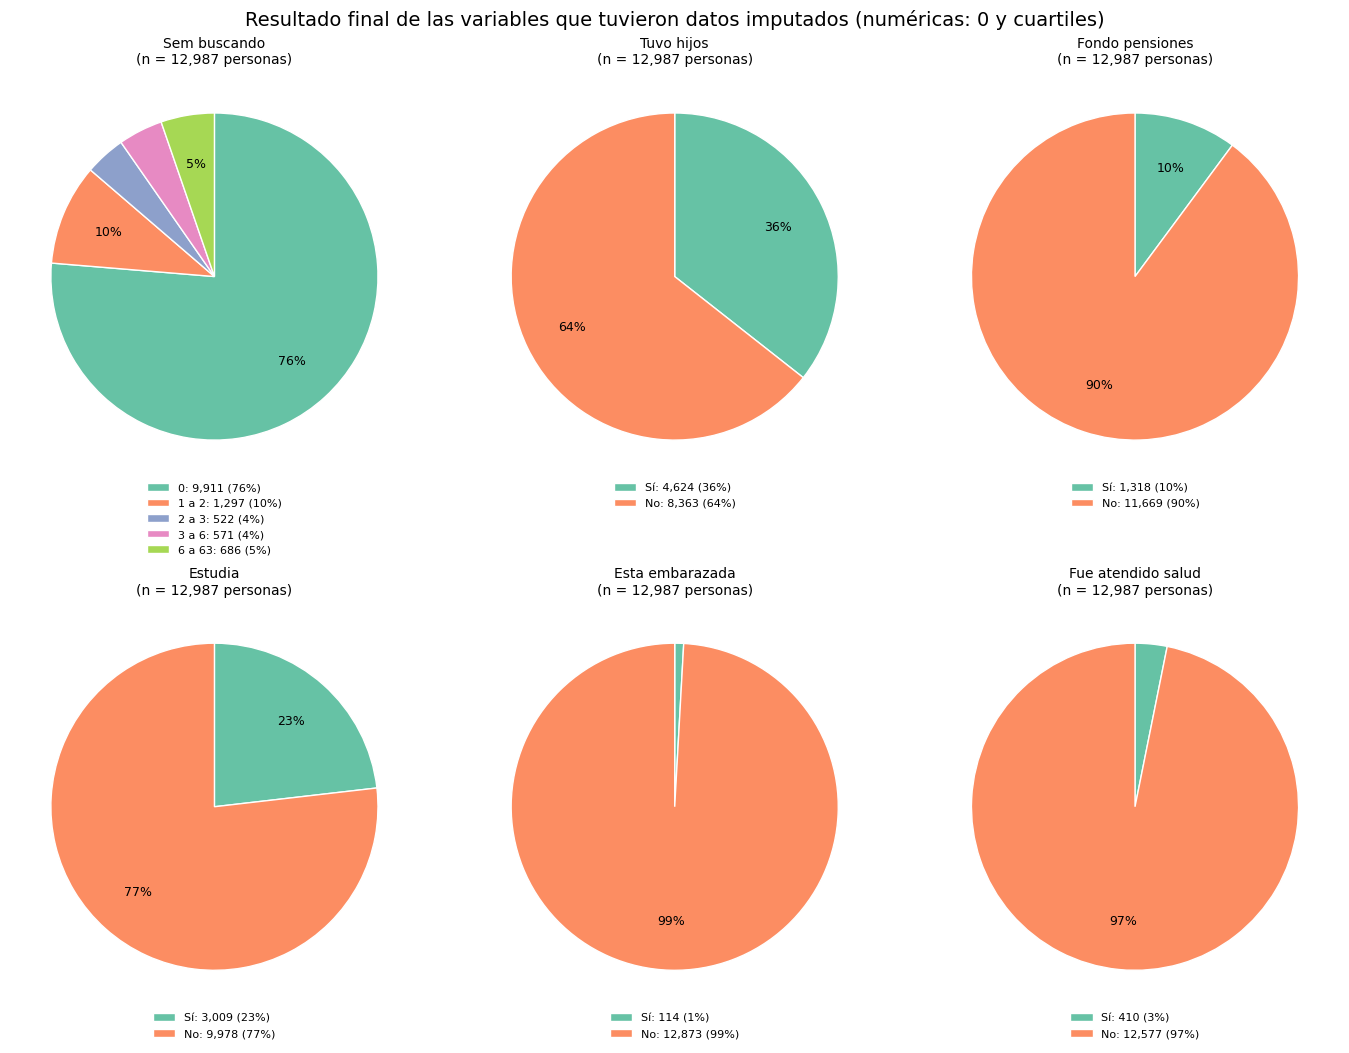

In [ ]:
ver = tabla_imp[tabla_imp.metodo != "sin imputar"]["variable"].tolist()[:MAX_TORTAS]
for i in range(0, len(ver), 6):
    bloque = ver[i:i + 6]
    tortas([conteo(hogares if c in COLS_HOGAR else df_limpio, c) for c in bloque],
           [nombre(c) for c in bloque],
           unidades=["hogares" if c in COLS_HOGAR else "personas" for c in bloque],
           suptitulo="Resultado final de las variables que tuvieron datos imputados (numéricas: 0 y cuartiles)")


=== PERFIL DEMOGRÁFICO (3 veredas vs. resto) ===
grupo                     A        B        C       D
personas            3821.00  5127.00  3444.00  595.00
hogares             1207.00  1725.00  1196.00  375.00
edad_media            29.66    31.87    34.10   40.29
edad_mediana          26.00    30.00    33.00   39.00
pct_mujeres           51.09    49.27    50.44   37.82
pct_menores_15        30.78    25.30    18.90    4.03
pct_65_mas             8.66     8.23     6.56    9.41
personas_por_hogar     3.17     2.97     2.88    1.59
razon_dependencia     65.13    50.44    34.16   15.53

=== TODAS LAS VEREDAS (ordenadas por población) ===
                 personas  hogares  edad_media  pct_mujeres  pct_menores_15  pct_65_mas
vereda_std                                                                             
SIN VEREDA           1842      679        33.6         53.3            23.0        10.6
TABACAL              1681      564        31.5         49.5            24.3         5.7
LA FU

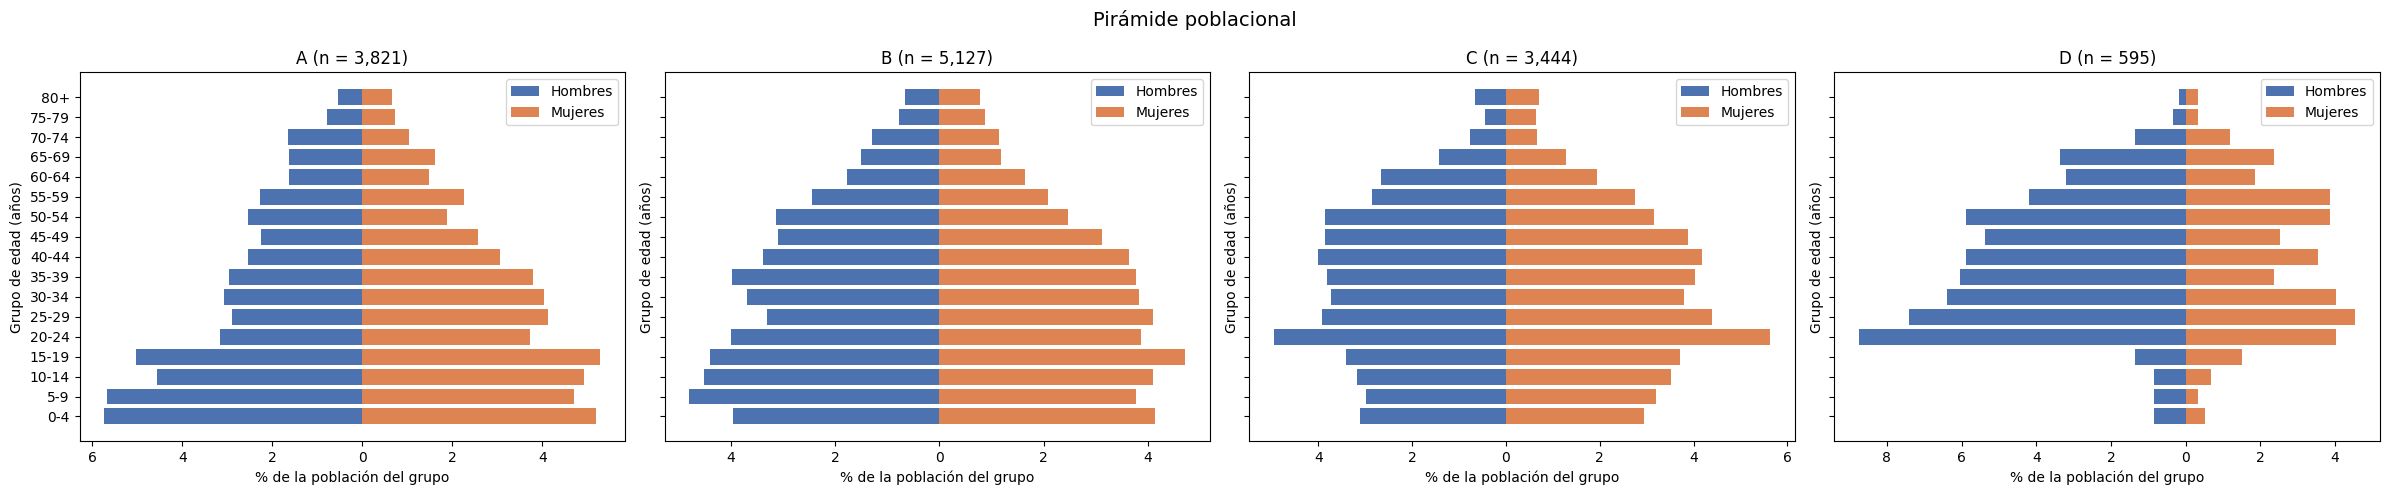

In [ ]:
gv = df_limpio["grupo"]
dem = pd.DataFrame({
    "personas": df_limpio.groupby("grupo").size(),
    "hogares": df_limpio.groupby("grupo")["hogar_id"].nunique(),
    "edad_media": df_limpio.groupby("grupo")["edad_calculada"].mean(),
    "edad_mediana": df_limpio.groupby("grupo")["edad_calculada"].median(),
    "pct_mujeres": pct(df_limpio["sexo_persona"] == 0, gv),
    "pct_menores_15": pct(df_limpio["edad_calculada"] < 15, gv),
    "pct_65_mas": pct(df_limpio["edad_calculada"] >= 65, gv),
})
dem["personas_por_hogar"] = dem["personas"] / dem["hogares"]
dependientes = (df_limpio["edad_calculada"] < 15) | (df_limpio["edad_calculada"] >= 65)
dem["razon_dependencia"] = dependientes.groupby(gv).sum() / df_limpio["edad_calculada"].between(15, 64).groupby(gv).sum() * 100
if "razon_dependencia" not in dem.columns or dem["razon_dependencia"].isna().all():
    dem["razon_dependencia"] = dependientes.groupby(gv).sum() / df_limpio["edad_calculada"].between(15, 64).groupby(gv).sum() * 100
print("\n=== PERFIL DEMOGRÁFICO (3 veredas vs. resto) ===")
print(dem.round(2).T)

todas = df_limpio.groupby("vereda_std").agg(personas=("hogar_id", "size"), hogares=("hogar_id", "nunique"),
                                            edad_media=("edad_calculada", "mean"))
todas["pct_mujeres"] = pct(df_limpio["sexo_persona"] == 0, df_limpio["vereda_std"])
todas["pct_menores_15"] = pct(df_limpio["edad_calculada"] < 15, df_limpio["vereda_std"])
todas["pct_65_mas"] = pct(df_limpio["edad_calculada"] >= 65, df_limpio["vereda_std"])
print("\n=== TODAS LAS VEREDAS (ordenadas por población) ===")
print(todas.sort_values("personas", ascending=False).round(1).to_string())

# Asegurar que VER no esté vacío y contenga los grupos reales presentes en los datos
VER = [v for v in df_limpio["grupo"].dropna().unique() if str(v).strip() != ""]
VER = sorted(VER)

fig, axes = plt.subplots(1, len(VER), figsize=(6 * len(VER), 5), sharey=True, squeeze=False)
for ax, v in zip(axes[0], VER):
    sub = df_limpio[df_limpio["grupo"] == v]
    if sub.empty:
        continue
    t = pd.crosstab(sub["grupo_edad"], sub["sexo"]).reindex(columns=["Hombre", "Mujer"], fill_value=0) / len(sub) * 100
    ax.barh(t.index.astype(str), -t["Hombre"], color="#4C72B0", label="Hombres")
    ax.barh(t.index.astype(str), t["Mujer"], color="#DD8452", label="Mujeres")
    ax.set_title(f"{v} (n = {len(sub):,})")
    ax.set_xlabel("% de la población del grupo")
    ax.set_ylabel("Grupo de edad (años)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{abs(x):.0f}"))
    ax.legend()
plt.suptitle("Pirámide poblacional", fontsize=14)
plt.tight_layout()
plt.show()

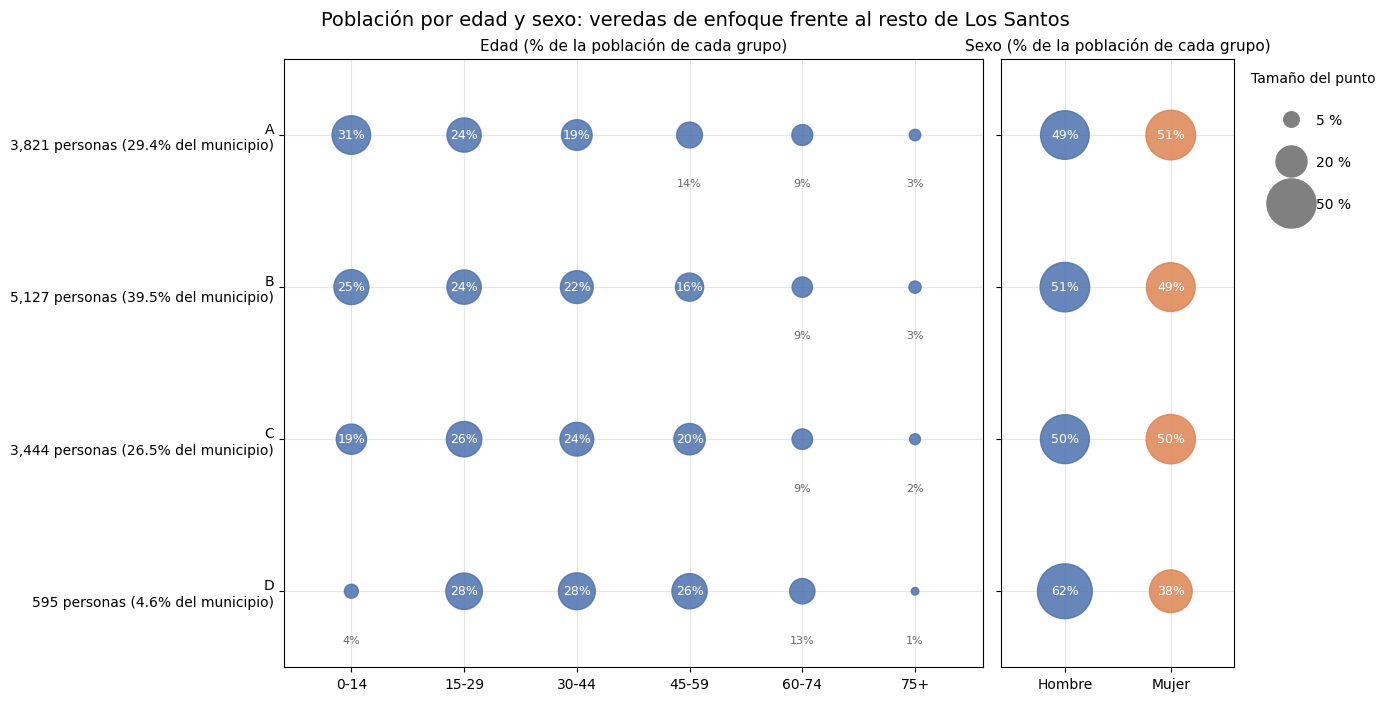

In [ ]:
def matriz_puntos(paneles, filas, etiquetas_filas, colores, suptitulo):
    """Una fila por grupo y una columna por categoría; el tamaño del punto es el % y el número se escribe en el gráfico."""
    anchos = [t.shape[1] for _, t in paneles]
    fig, axes = plt.subplots(1, len(paneles), sharey=True, layout="constrained", gridspec_kw={"width_ratios": anchos},
                             figsize=(sum(anchos) * 1.1 + 5, 1.1 * len(filas) + 2.5))
    for ax, (titulo, tabla), color in zip(axes, paneles, colores):
        tabla = tabla.reindex(filas).fillna(0)
        x, y = np.meshgrid(range(tabla.shape[1]), range(len(filas)))
        x, y, v = x.ravel(), y.ravel(), tabla.values.ravel()
        ax.scatter(x, y, s=v * 25, c=[color[i] for i in x] if isinstance(color, list) else color, alpha=0.85)
        for xi, yi, vi in zip(x, y, v):
            dentro = vi >= 15                                     # punto grande: número adentro; pequeño: debajo
            ax.text(xi, yi + (0 if dentro else 0.32), f"{vi:.0f}%", ha="center", va="center",
                    fontsize=9 if dentro else 8, color="white" if dentro else "dimgray")
        ax.set_xticks(range(tabla.shape[1]))
        ax.set_xticklabels(tabla.columns.astype(str), fontsize=10)
        ax.set_xlim(-0.6, tabla.shape[1] - 0.4)
        ax.set_ylim(len(filas) - 0.5, -0.5)
        ax.set_title(titulo, fontsize=11)
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
    axes[0].set_yticks(range(len(filas)))
    axes[0].set_yticklabels(etiquetas_filas, fontsize=10)
    for marca, v in zip(axes[0].get_yticklabels(), filas):
        if v in OBJETIVO:
            marca.set_fontweight("bold")
    tamanos = [plt.Line2D([], [], marker="o", linestyle="", color="gray", markersize=np.sqrt(p * 25)) for p in (5, 20, 50)]
    axes[-1].legend(tamanos, ["5 %", "20 %", "50 %"], title="Tamaño del punto", loc="upper left",
                    bbox_to_anchor=(1.02, 1), frameon=False, labelspacing=2)
    fig.suptitle(suptitulo, fontsize=14)
    plt.show()

personas_grupo = df_limpio["grupo"].value_counts()
edad_g = pd.cut(df_limpio["edad_calculada"], [0, 15, 30, 45, 60, 75, 200], right=False,
                labels=["0-14", "15-29", "30-44", "45-59", "60-74", "75+"])
matriz_puntos(
    [("Edad (% de la población de cada grupo)", pd.crosstab(df_limpio["grupo"], edad_g, normalize="index") * 100),
     ("Sexo (% de la población de cada grupo)",
      pd.crosstab(df_limpio["grupo"], df_limpio["sexo"], normalize="index").reindex(columns=["Hombre", "Mujer"], fill_value=0) * 100)],
    VER, [f"{v}\n{personas_grupo[v]:,} personas ({personas_grupo[v] / len(df_limpio):.1%} del municipio)" for v in VER],
    ["#4C72B0", ["#4C72B0", "#DD8452"]], "Población por edad y sexo: veredas de enfoque frente al resto de Los Santos")



=== % DE HOGARES QUE TIENEN SERVICIO / BIEN ===
grupo                    A     B     C     D
Tiene energia         95.3  97.1  97.5  97.6
Tiene acueducto        7.6  12.6  15.0  18.0
Tiene alcantarillado   6.8  11.9  14.0  16.9
Tiene gas              3.5   7.4   7.6   8.1
Tiene recoleccion     33.3  46.5  54.5  55.6
Tiene internet         0.2   1.0   1.4   4.3
Tiene nevera          44.3  51.7  54.8  37.6
Tiene lavadora         4.1   6.4   9.0  12.9
Tiene pc               0.2   0.7   1.2   5.4
Tiene moto             6.2   9.8  11.9  14.0
Tiene carro            0.5   1.2   2.3   7.0
Tiene tractor          0.3   0.0   0.1   0.0
Tiene bien raiz        1.9   3.6   5.1   8.1


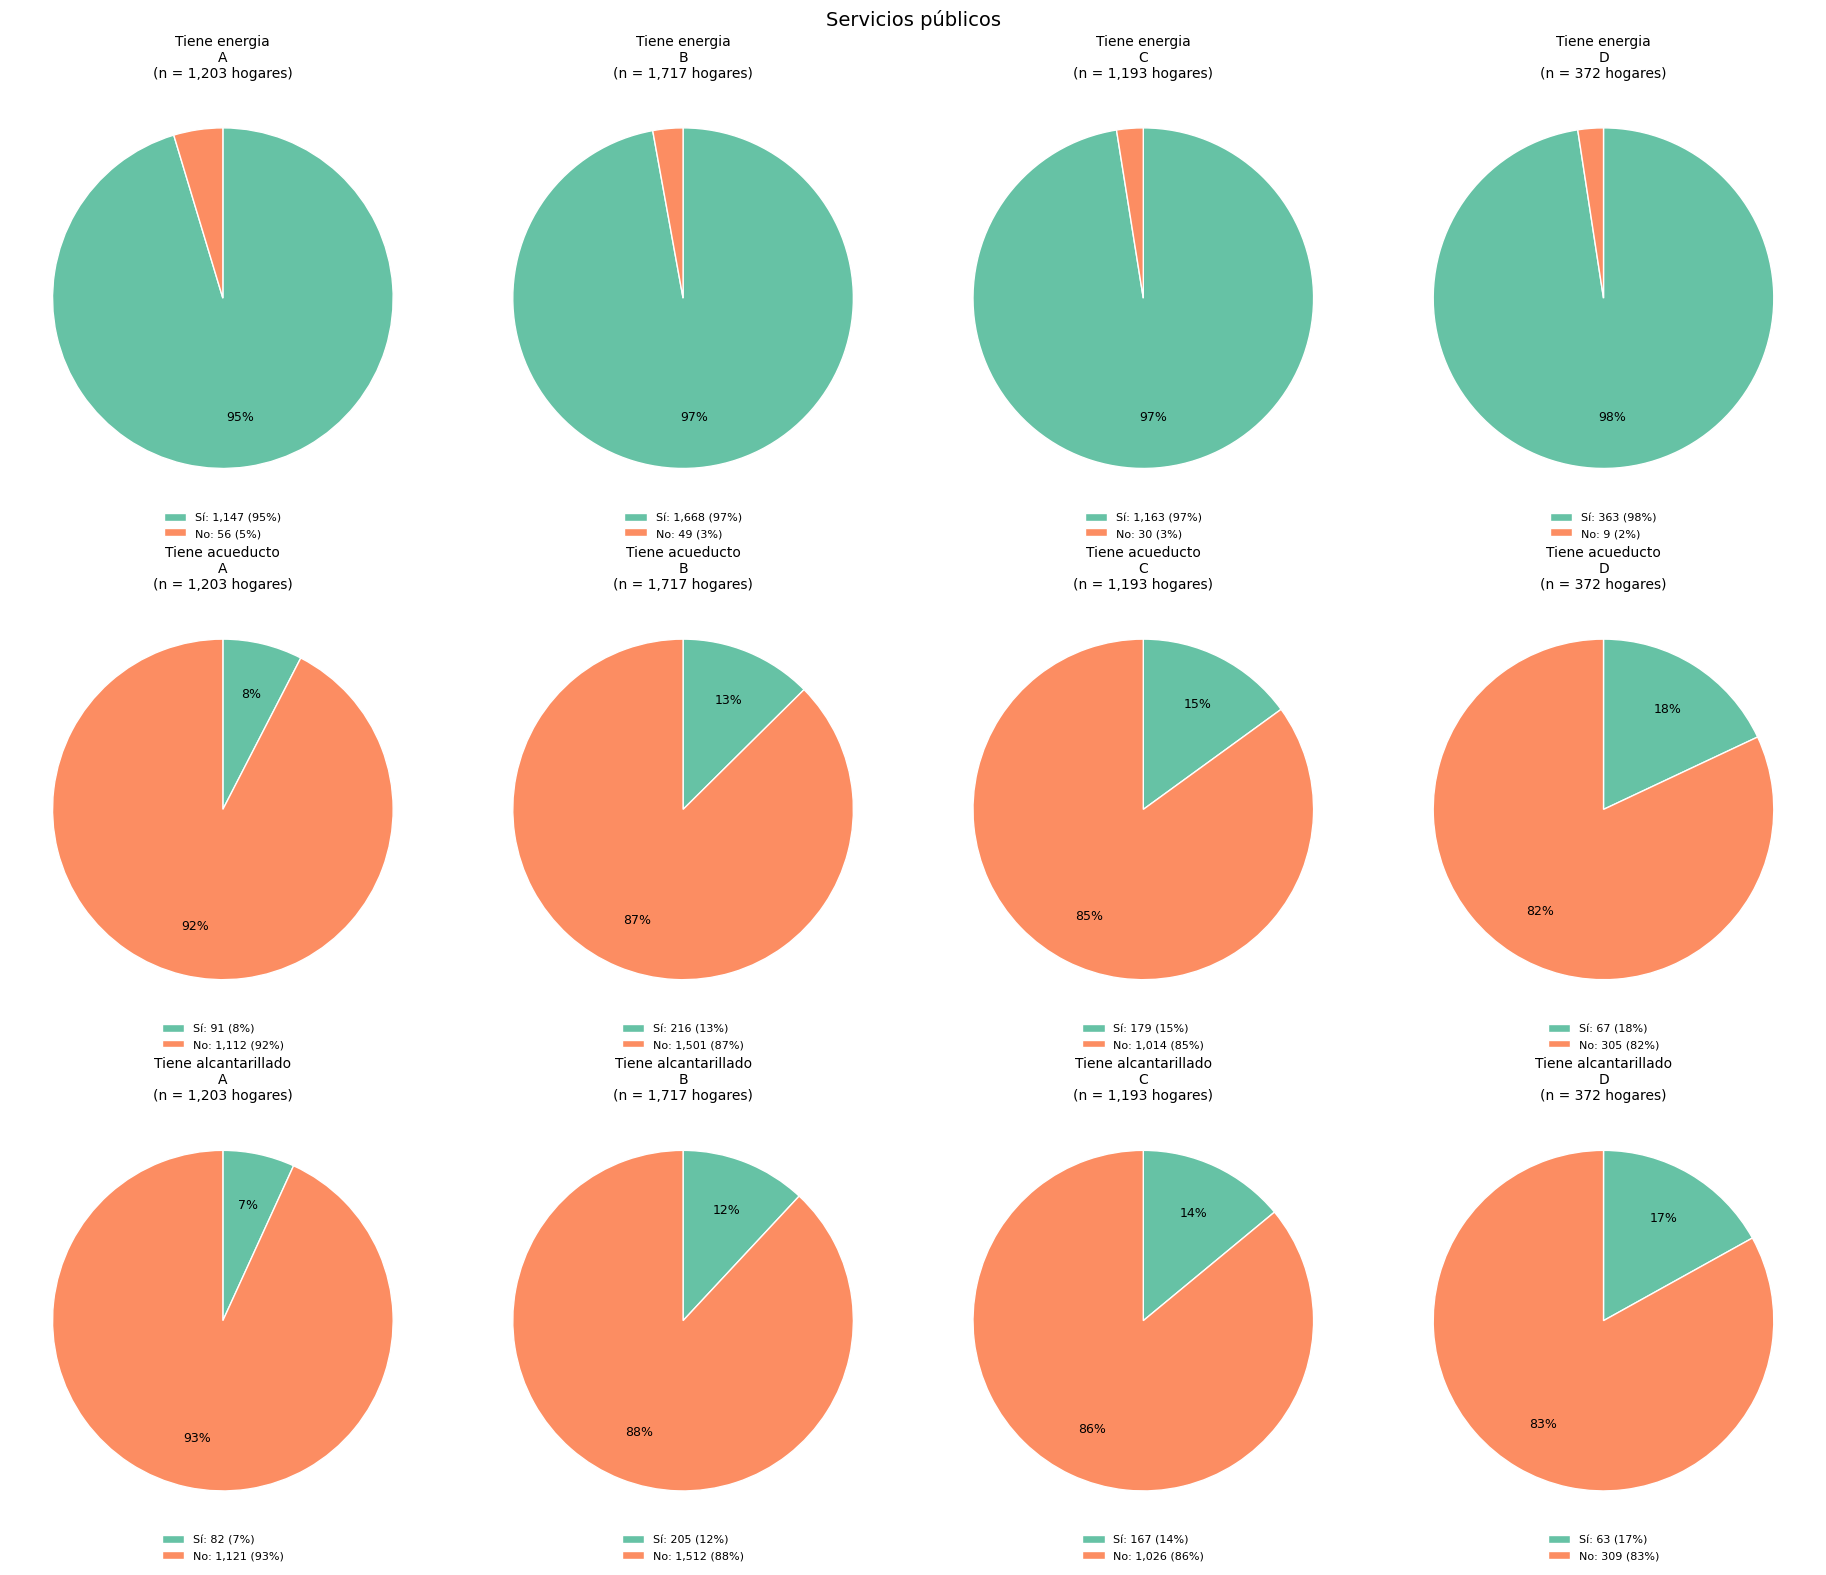

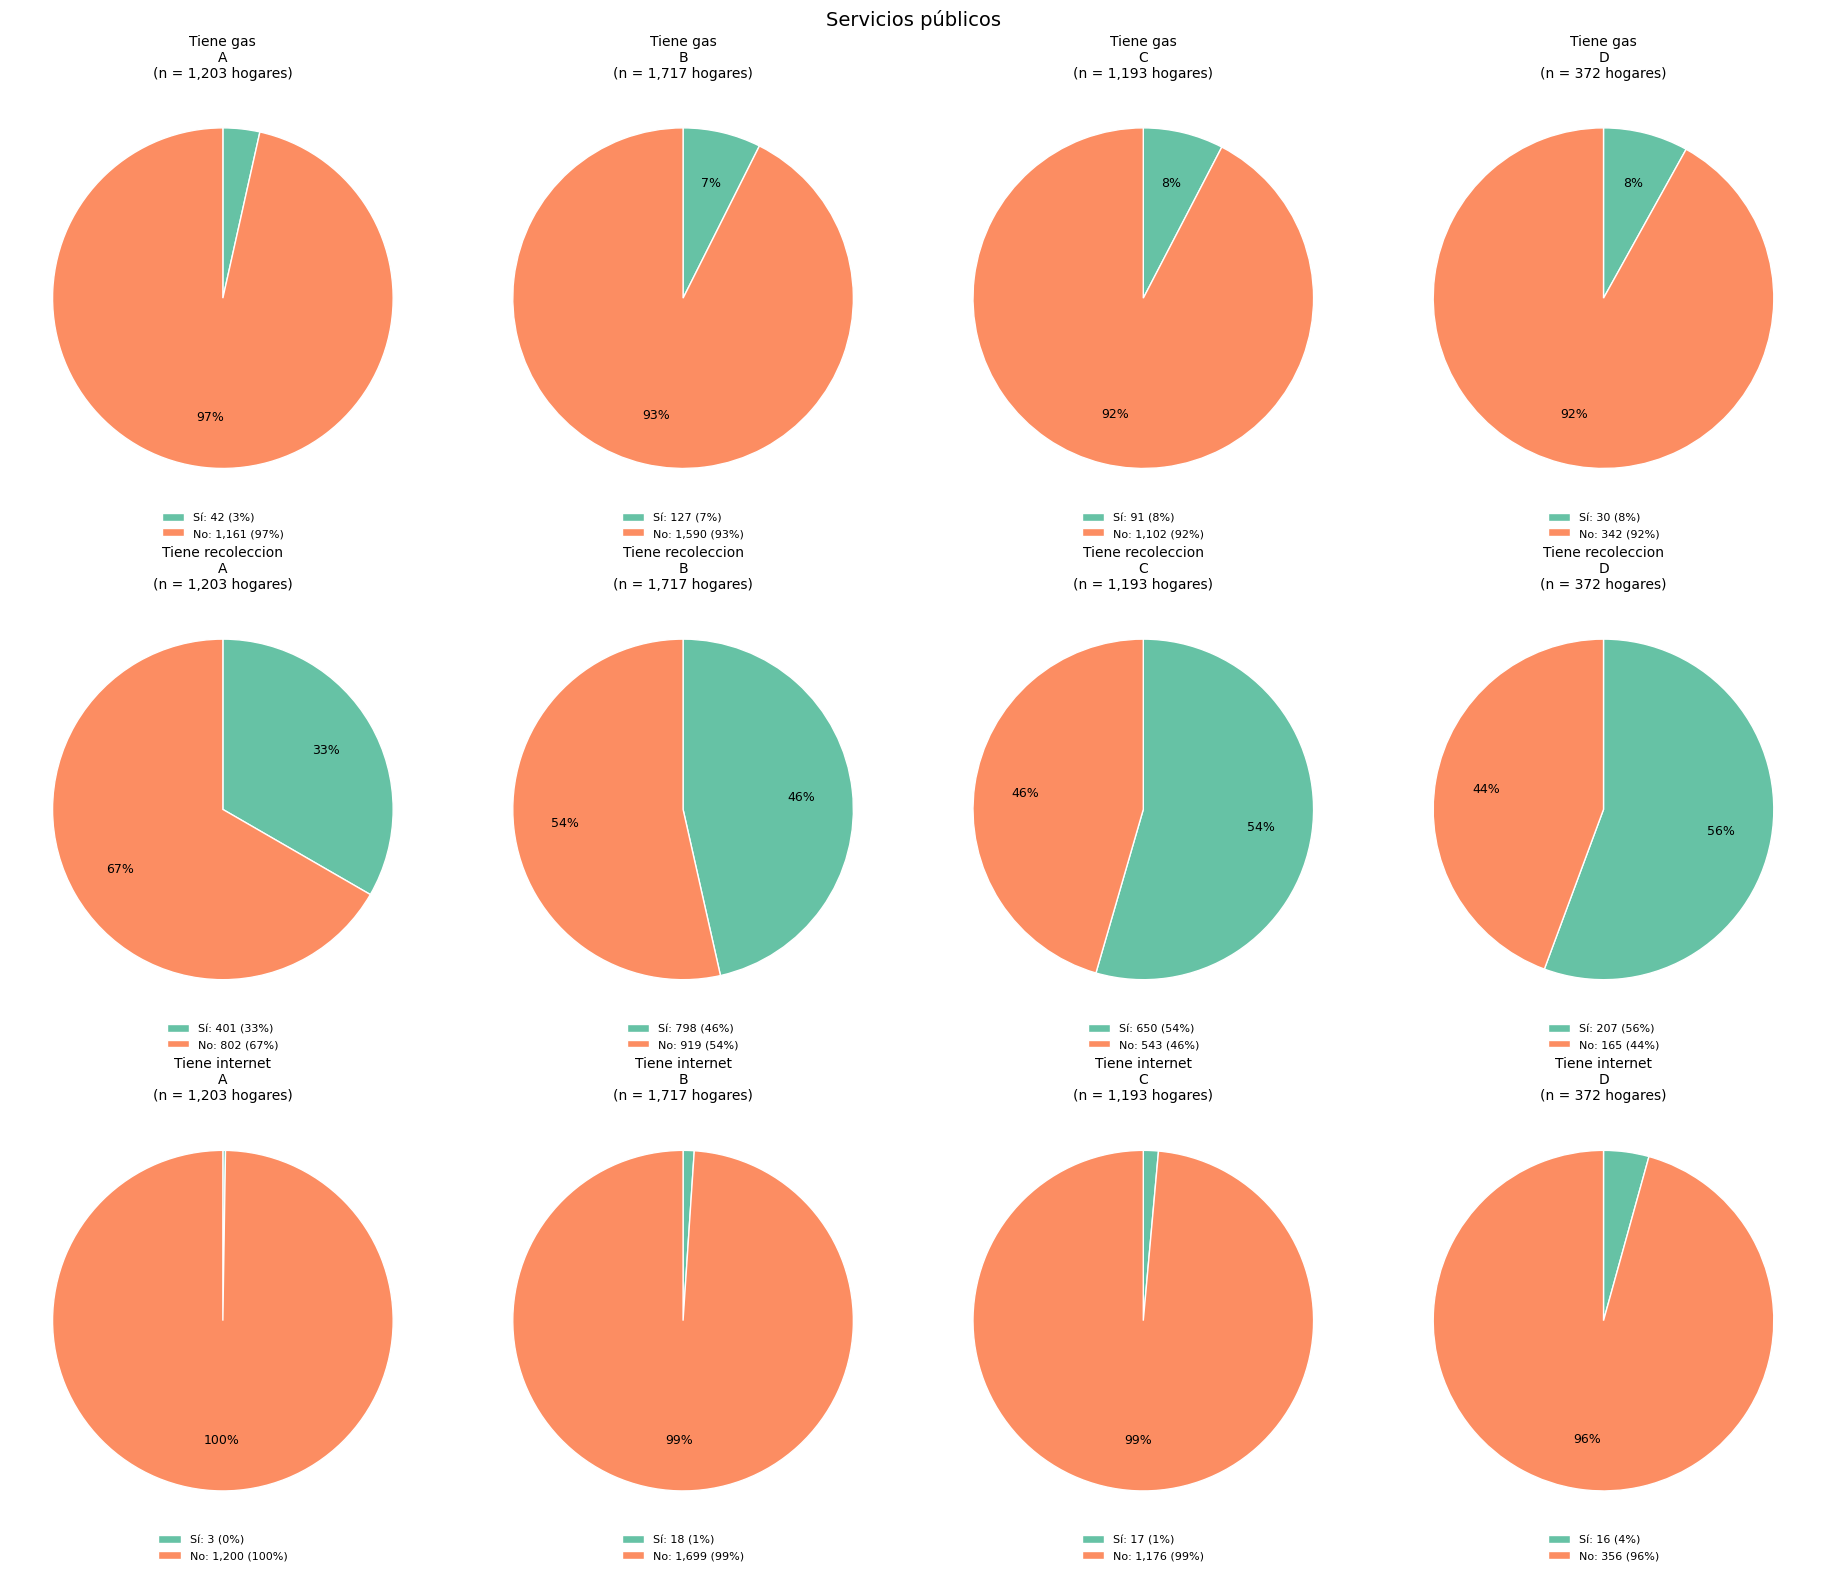

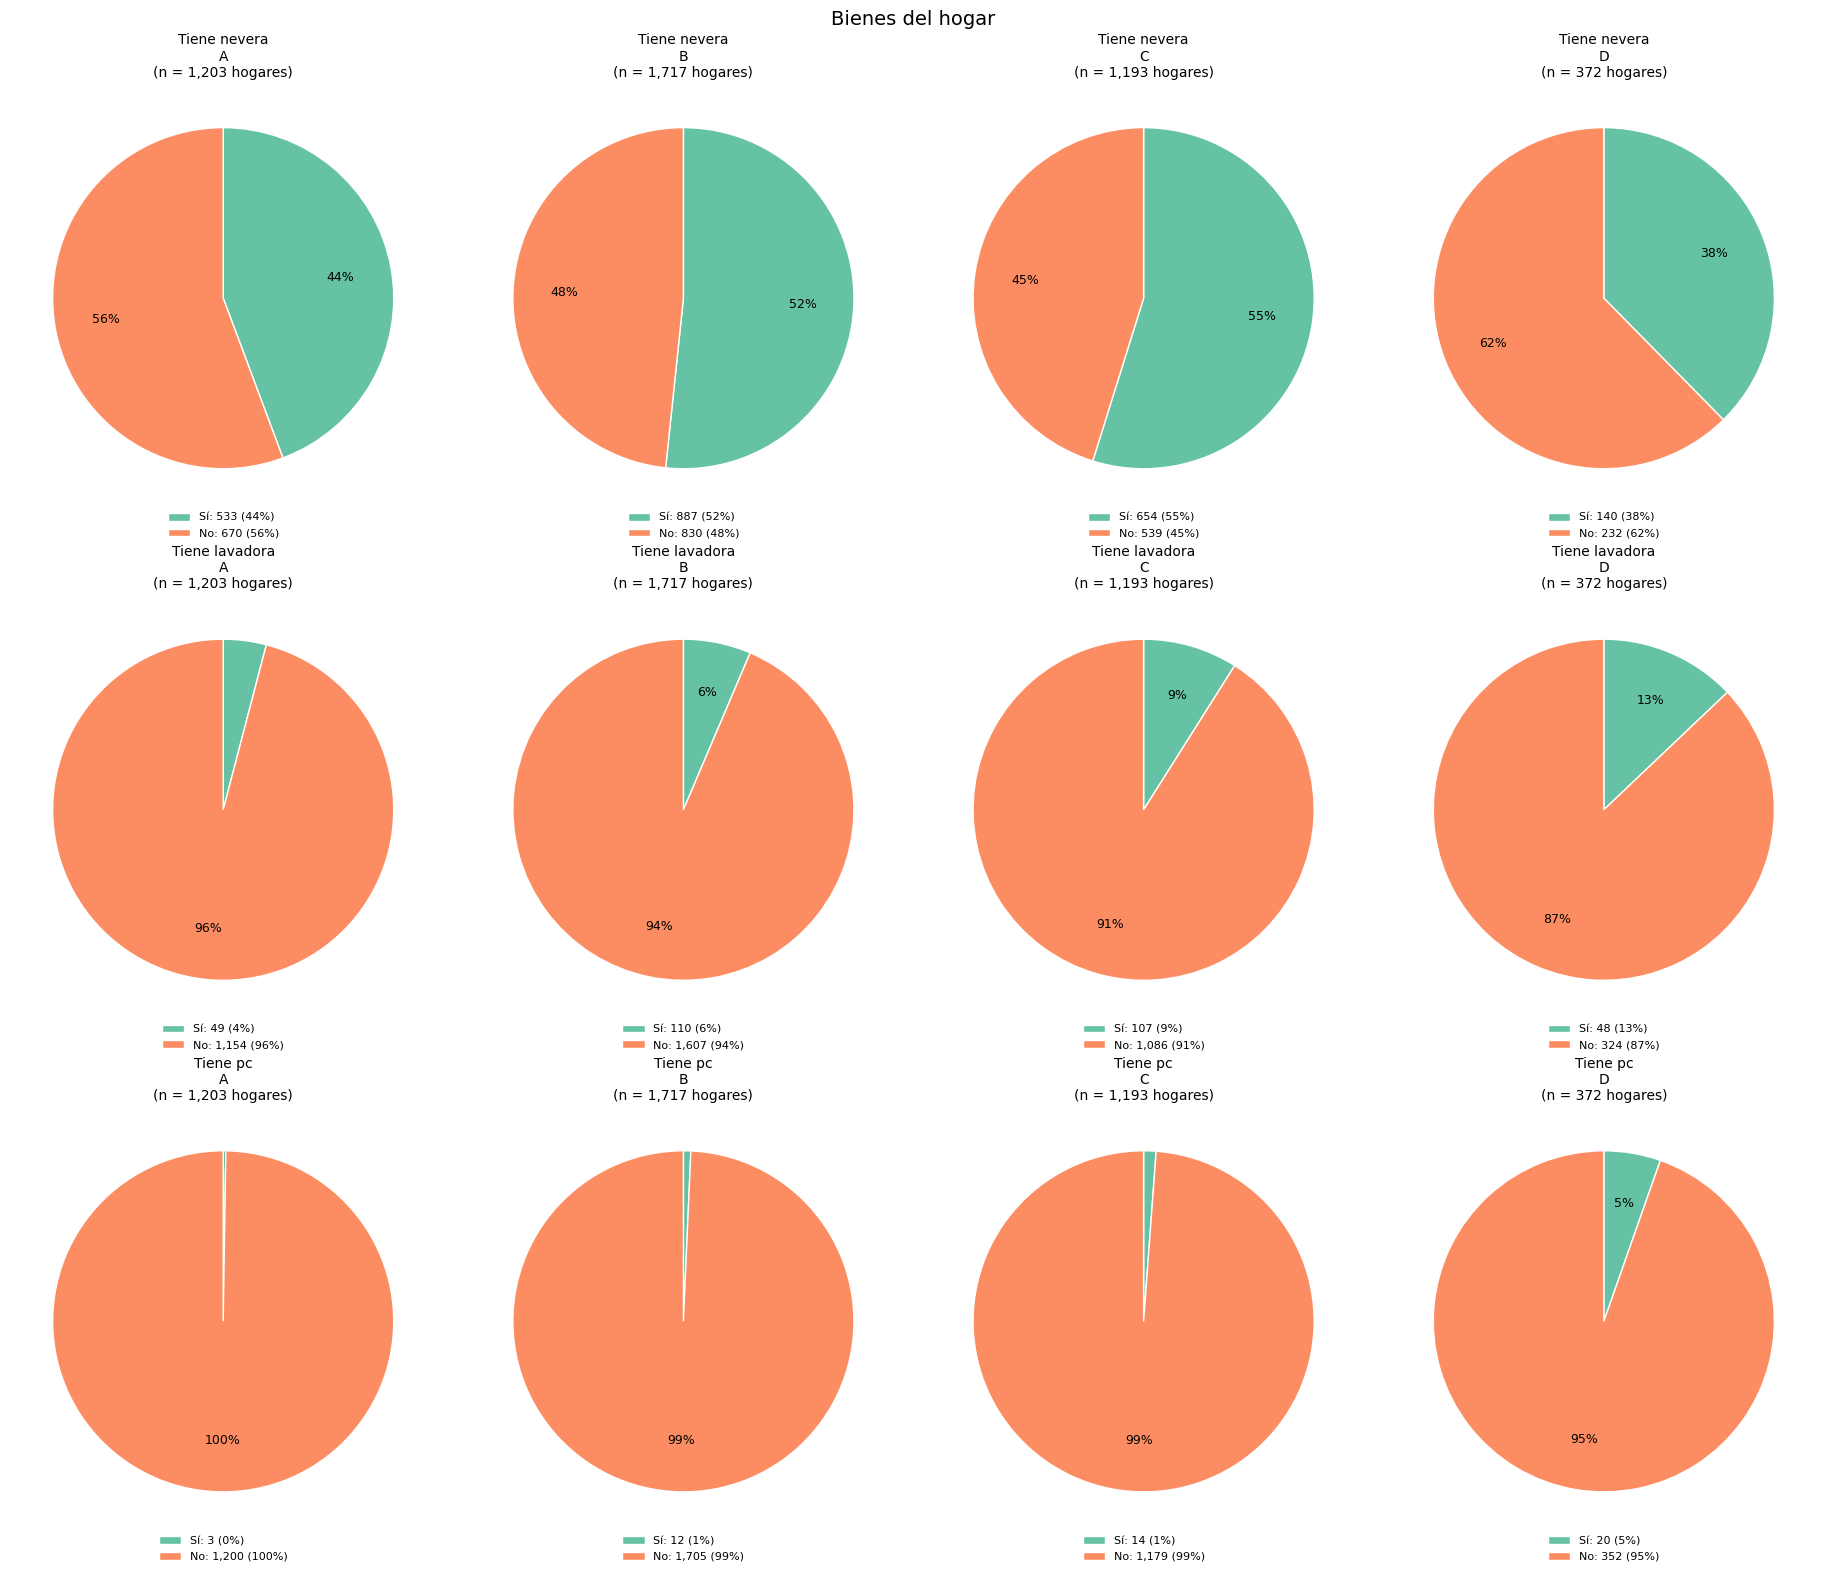

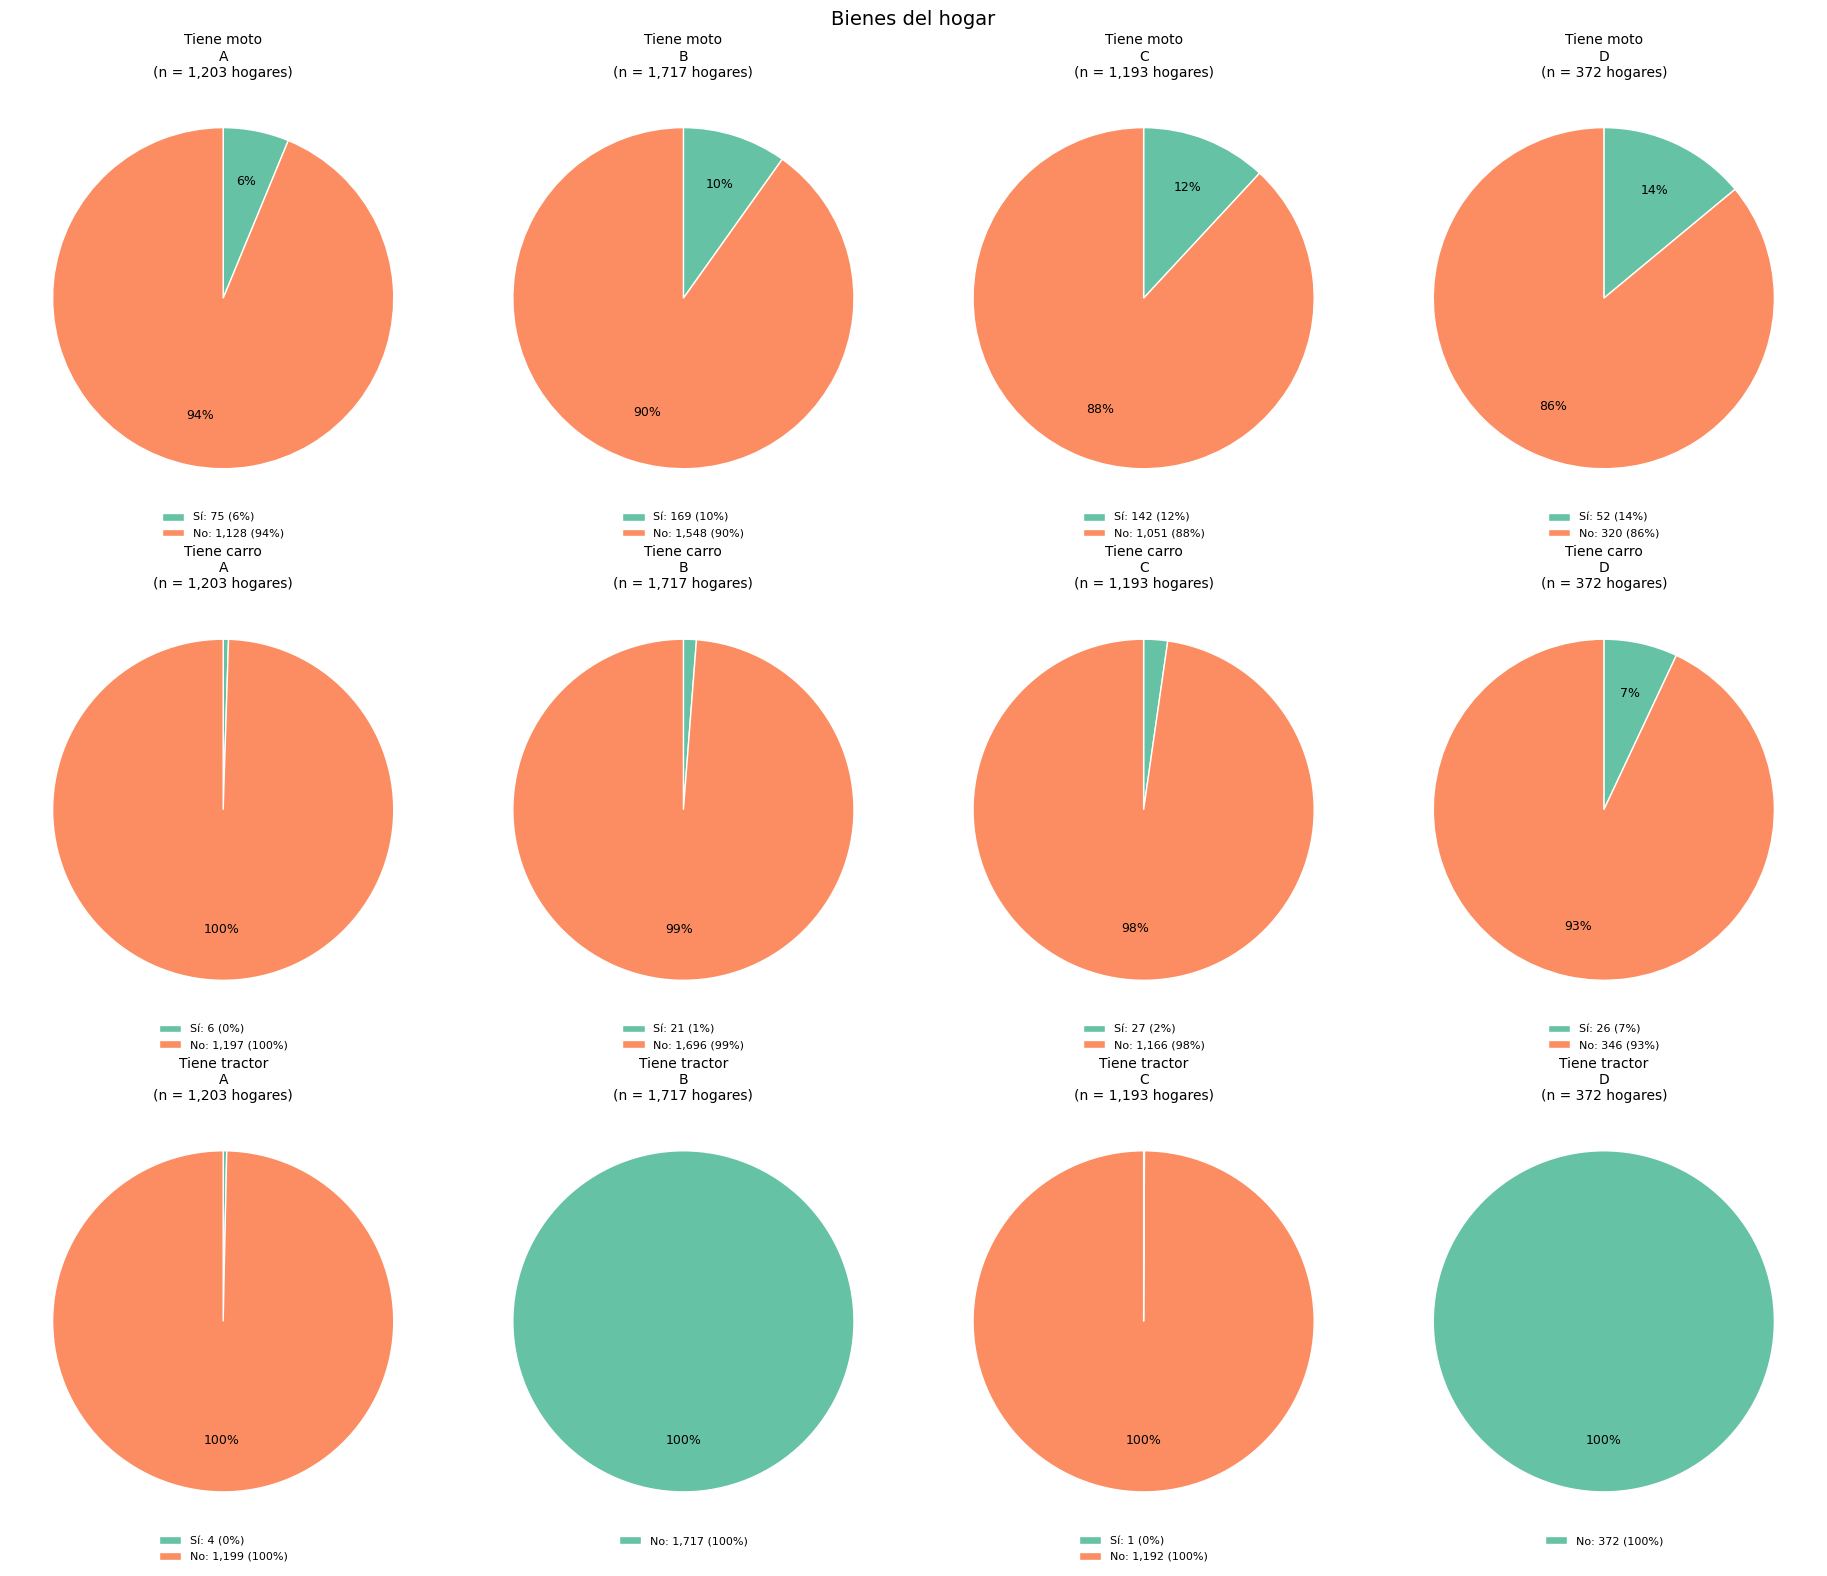

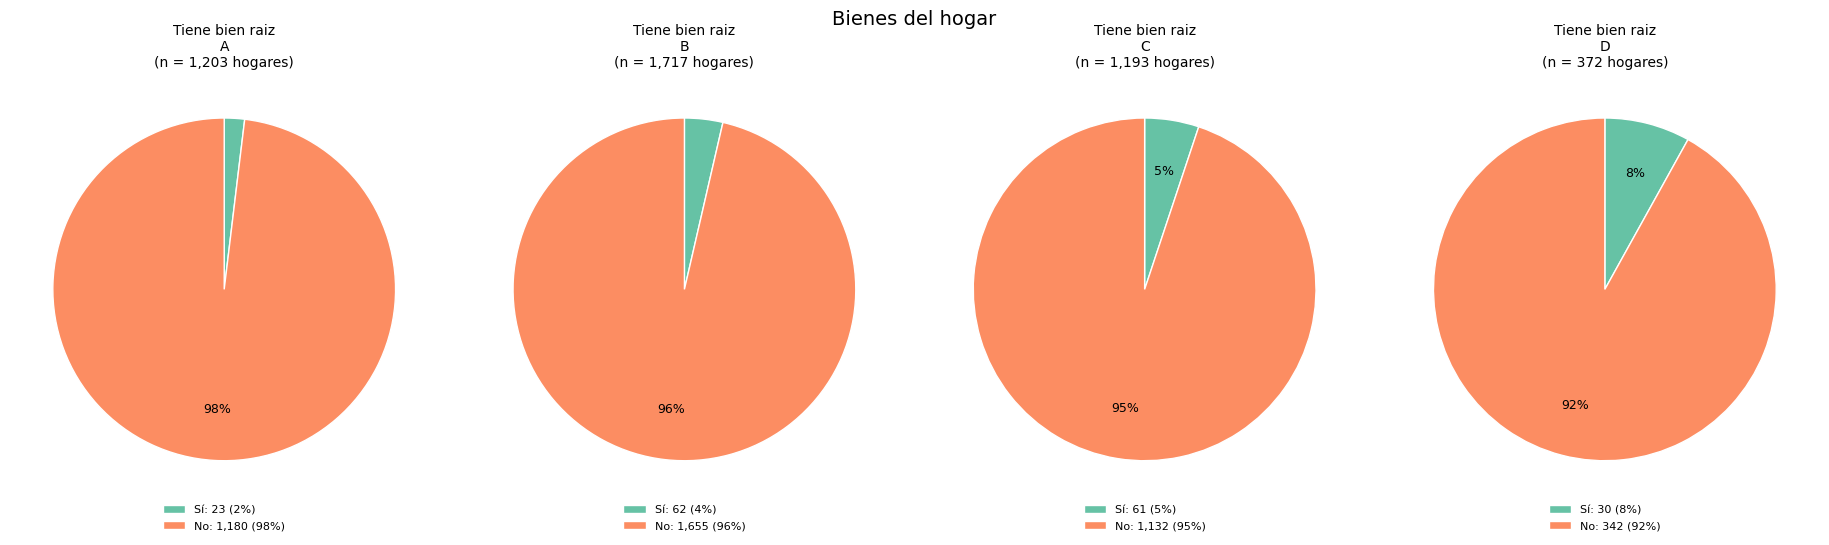

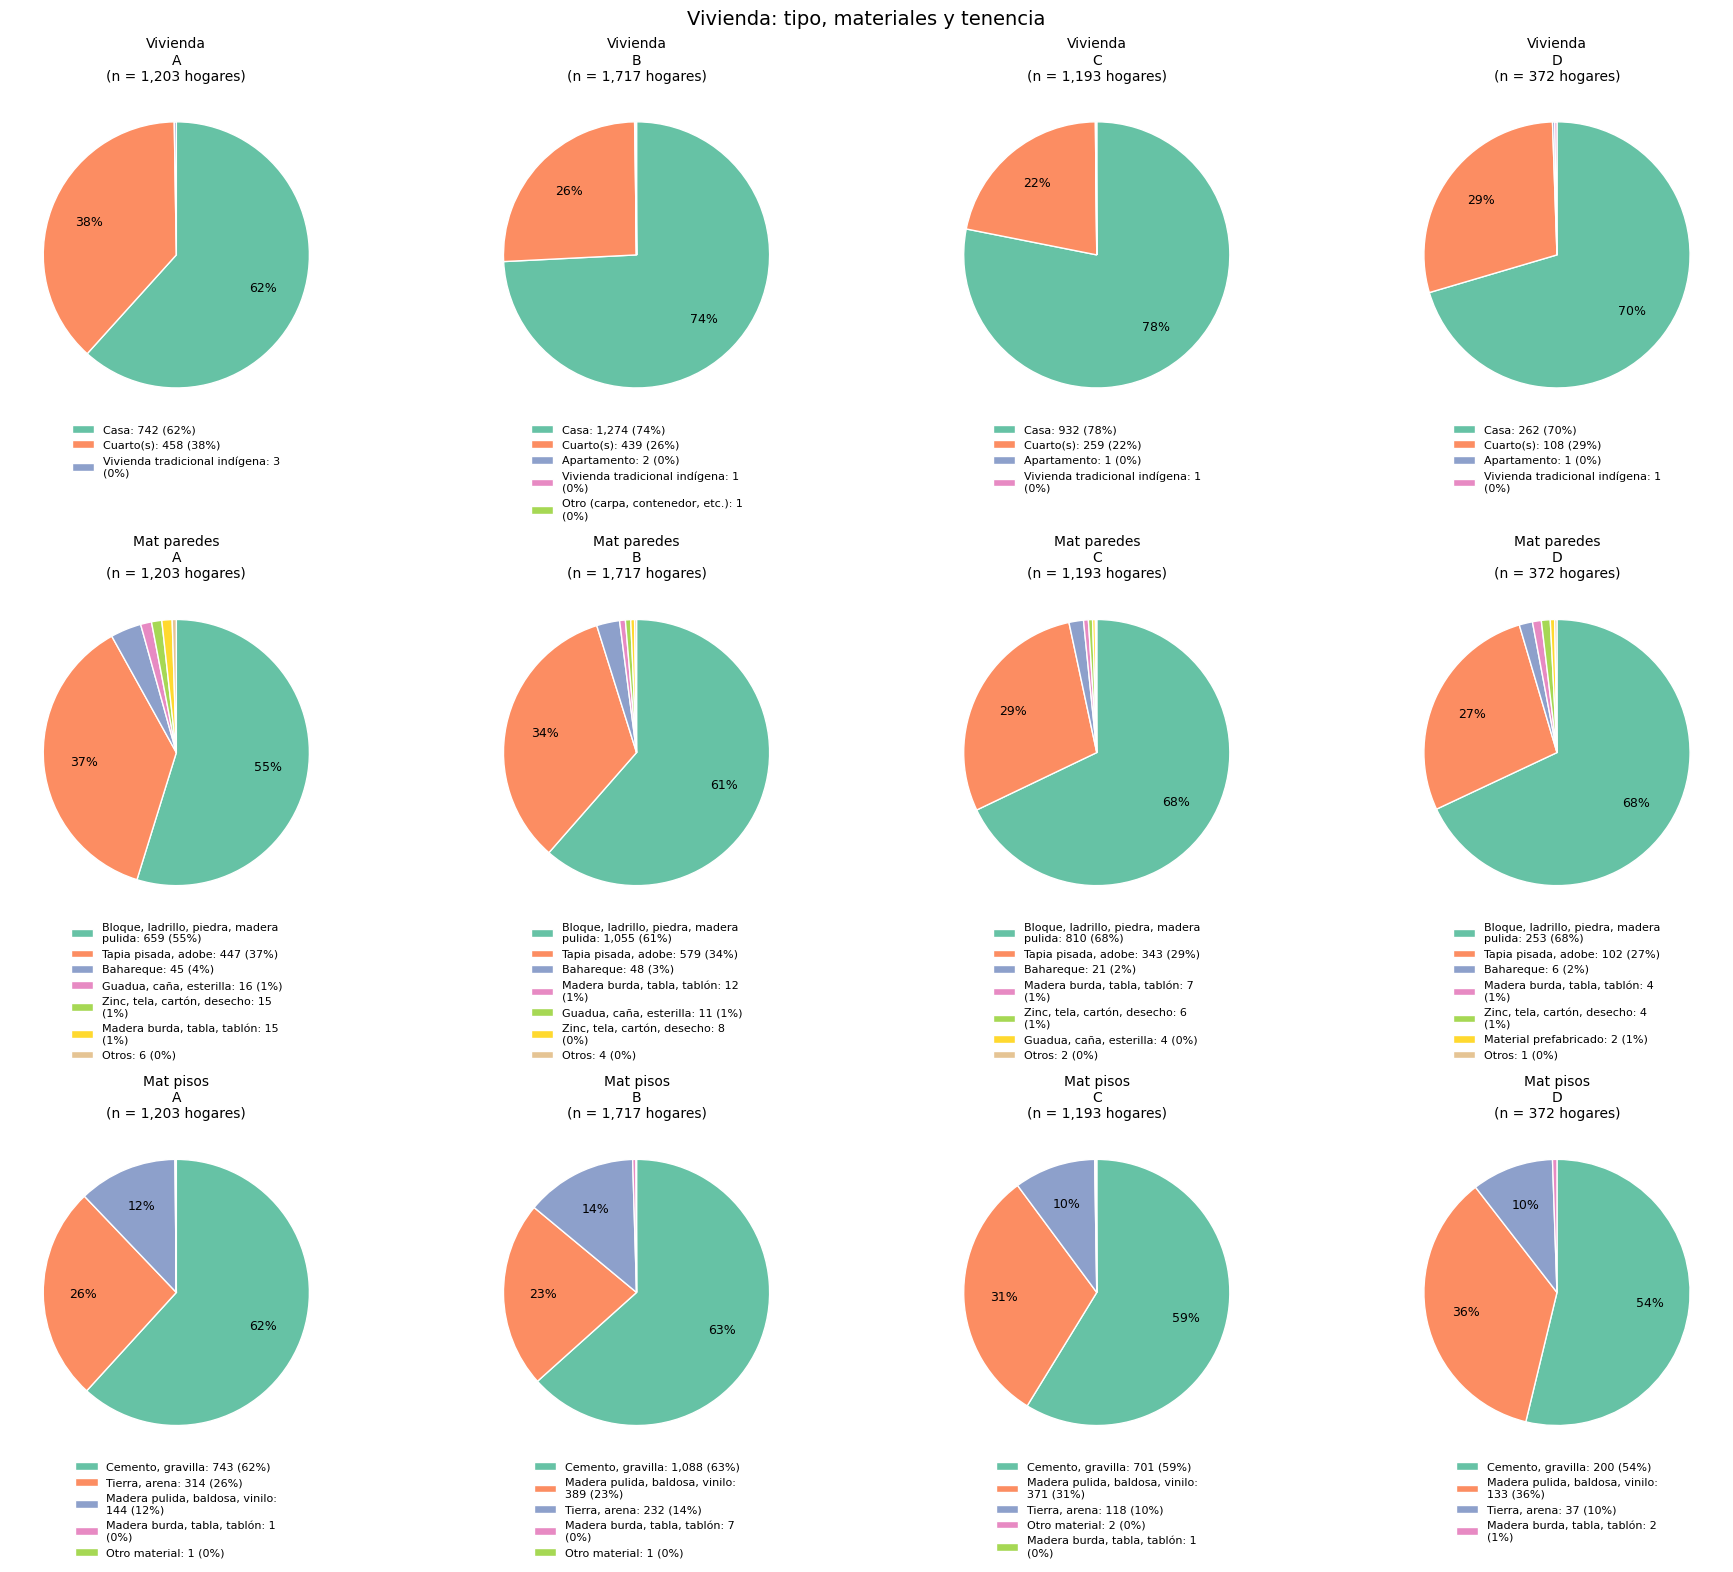

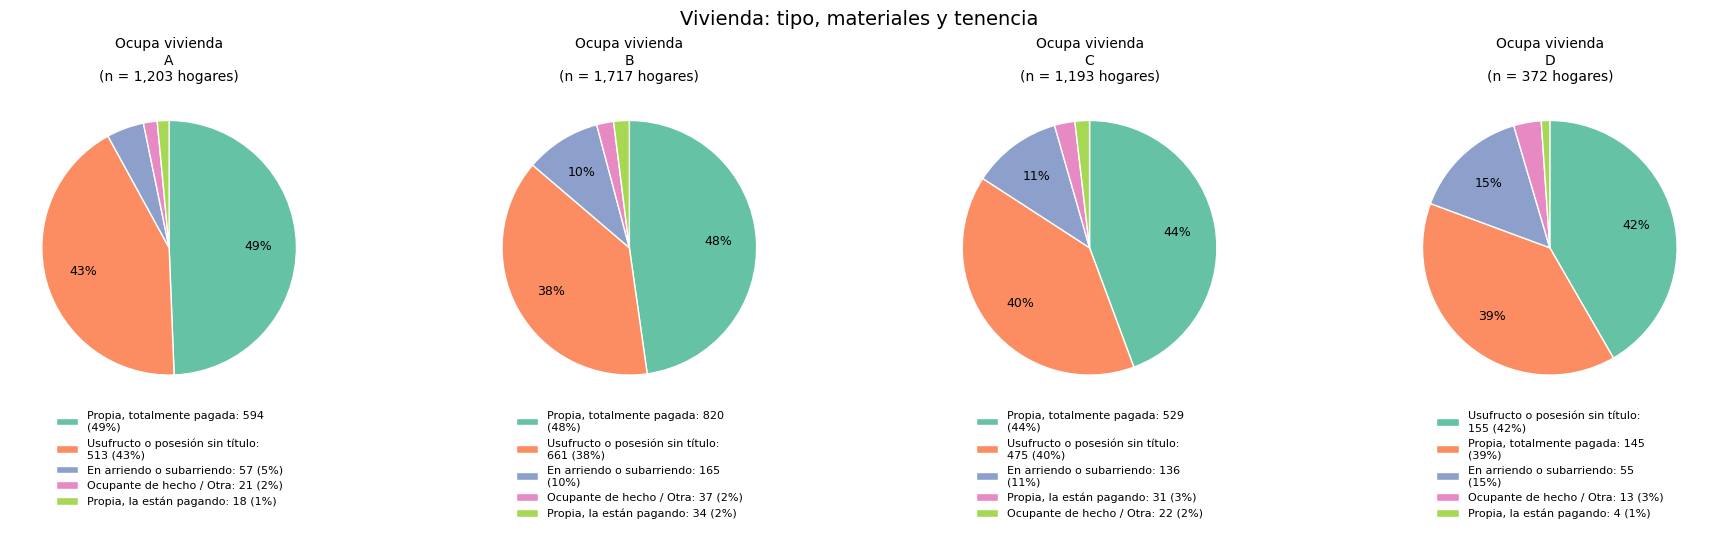

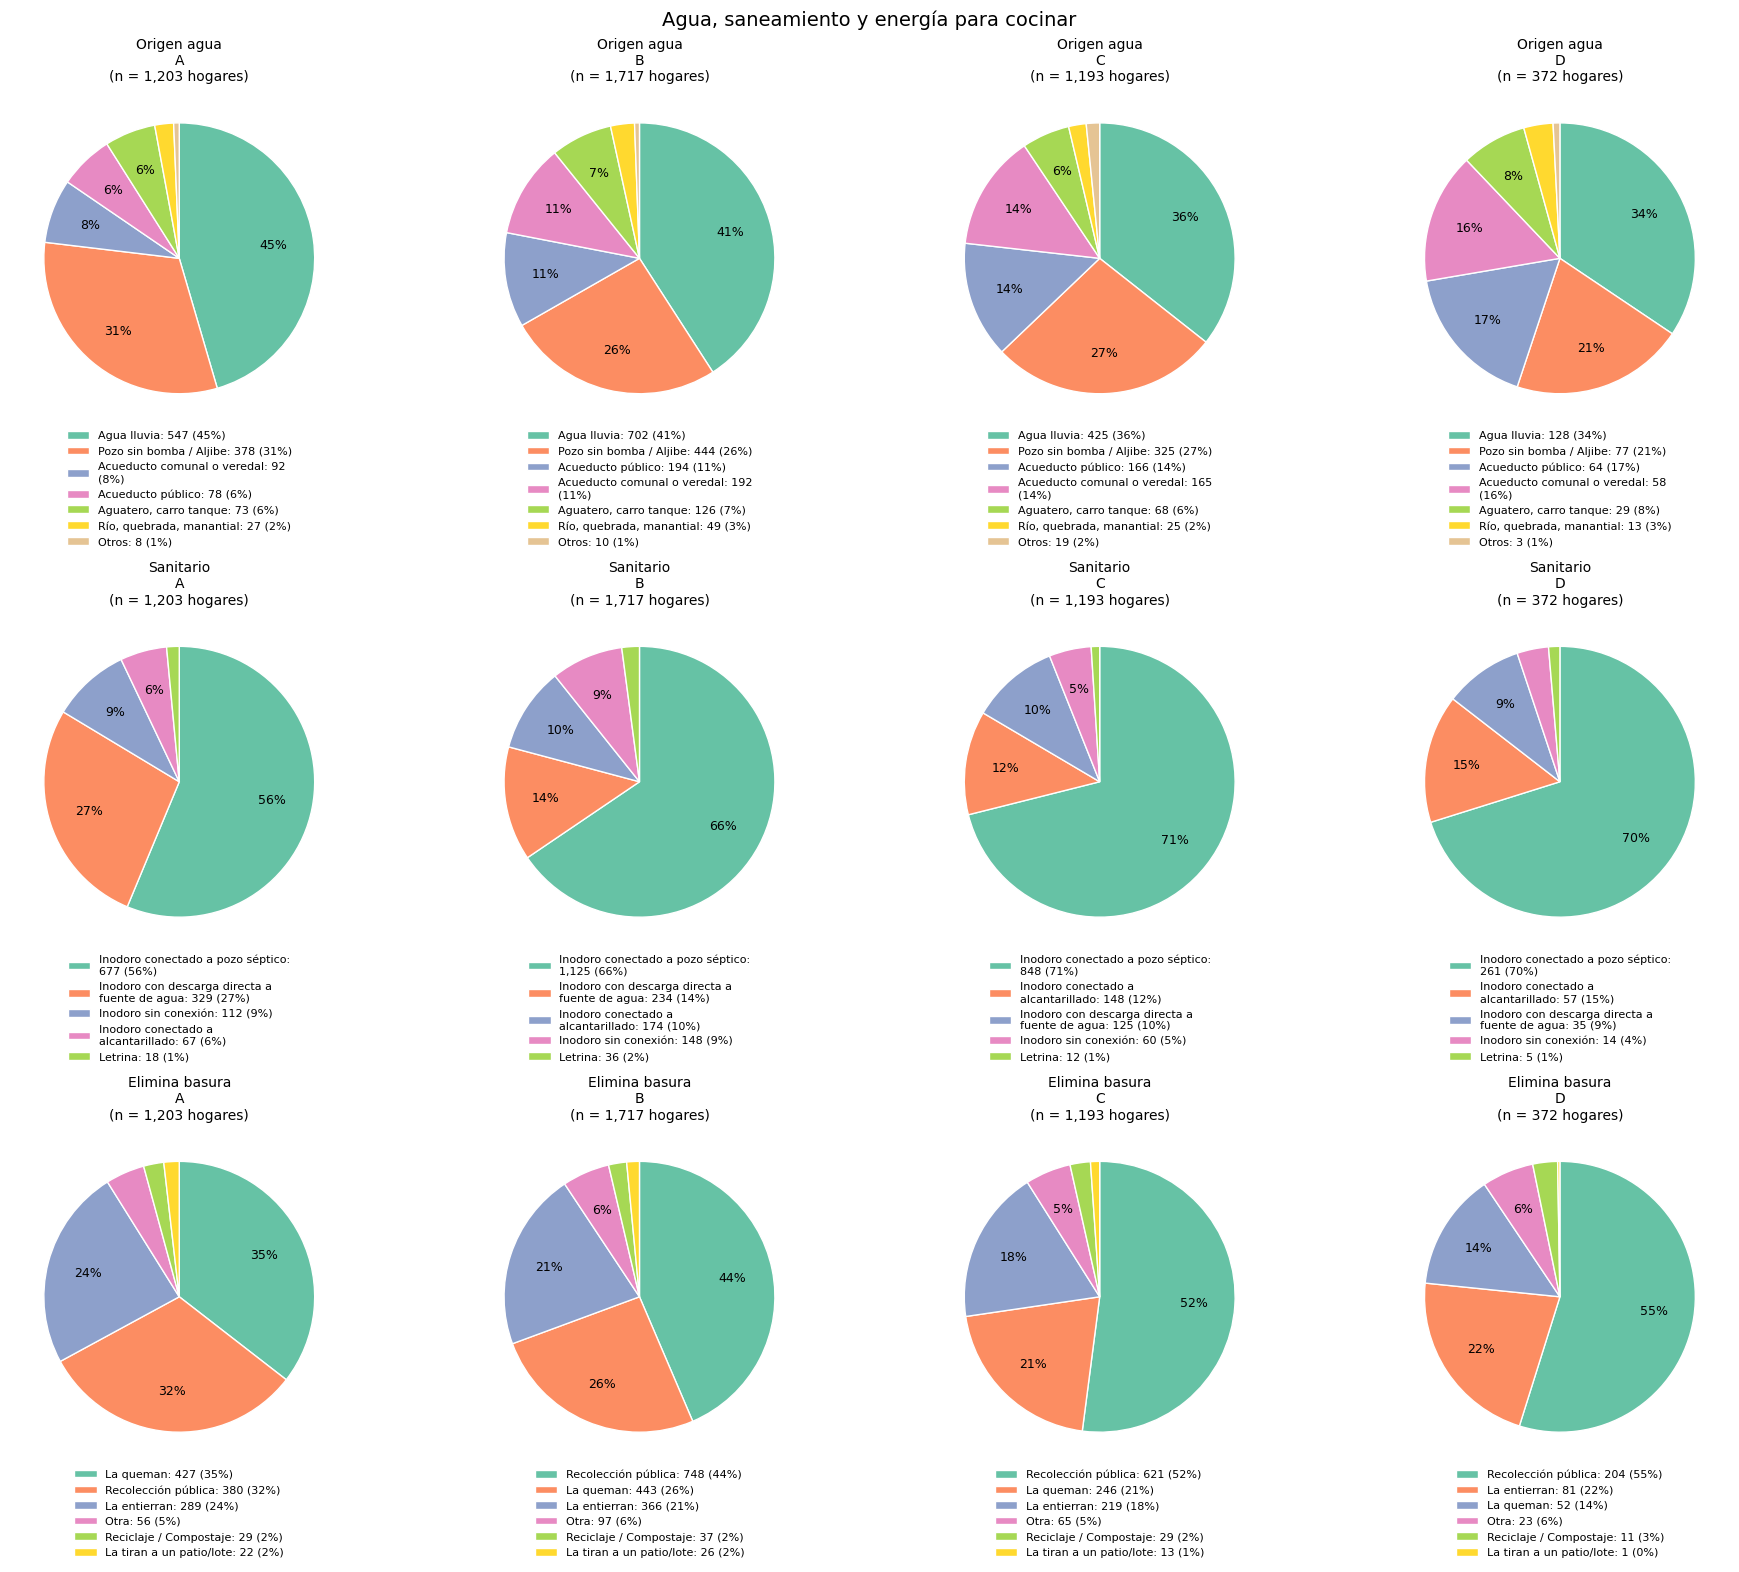

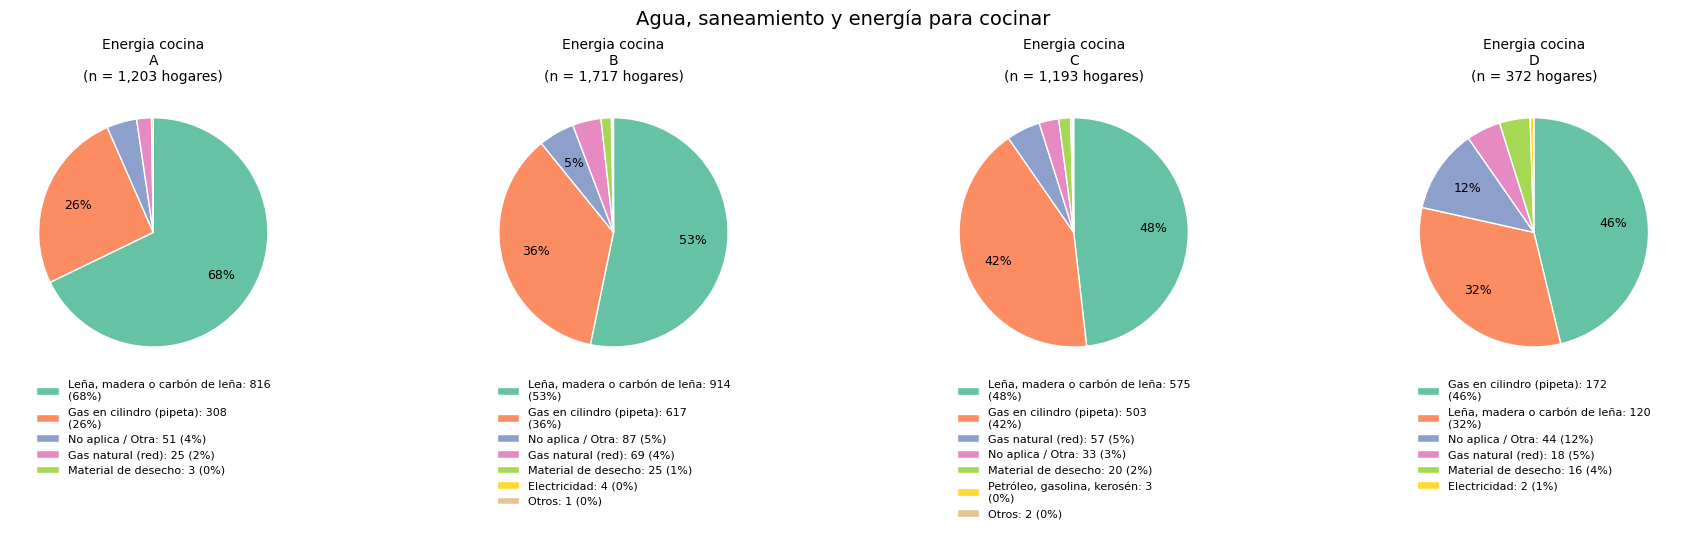


=== HACINAMIENTO (personas por dormitorio) ===
       mean  median  pct_hacinamiento(>3)
grupo                                    
A      2.76     3.0                 25.27
B      2.47     2.0                 22.31
C      2.38     2.0                 16.76
D      1.35     1.0                  2.69


In [ ]:
servicios = existentes(["ind_tiene_energia", "ind_tiene_acueducto", "ind_tiene_alcantarillado",
                        "ind_tiene_gas", "ind_tiene_recoleccion", "ind_tiene_internet"])
bienes = existentes(["ind_tiene_nevera", "ind_tiene_lavadora", "ind_tiene_pc", "ind_tiene_moto",
                     "ind_tiene_carro", "ind_tiene_tractor", "ind_tiene_bien_raiz"])
print("\n=== % DE HOGARES QUE TIENEN SERVICIO / BIEN ===")
print(pd.DataFrame({nombre(c): pct(hogares[c] == 1, hogares["grupo"]) for c in servicios + bienes}).T.round(1))

tortas_por_vereda(hogares, servicios, "Servicios públicos", unidad="hogares")
tortas_por_vereda(hogares, bienes, "Bienes del hogar", unidad="hogares")
tortas_por_vereda(hogares, existentes(["tip_vivienda", "tip_mat_paredes", "tip_mat_pisos", "tip_ocupa_vivienda"]),
                  "Vivienda: tipo, materiales y tenencia", unidad="hogares")
tortas_por_vereda(hogares, existentes(["tip_origen_agua", "tip_sanitario", "tip_elimina_basura", "tip_energia_cocina"]),
                  "Agua, saneamiento y energía para cocinar", unidad="hogares")

if {"num_personas_hogar", "num_cuartos_dormir"}.issubset(hogares.columns):
    hogares["personas_por_dormitorio"] = hogares["num_personas_hogar"] / hogares["num_cuartos_dormir"].replace(0, np.nan)
    hac = hogares.groupby("grupo")["personas_por_dormitorio"].agg(["mean", "median"])
    hac["pct_hacinamiento(>3)"] = pct(hogares["personas_por_dormitorio"] > 3, hogares["grupo"])
    print("\n=== HACINAMIENTO (personas por dormitorio) ===")
    print(hac.round(2))



% de analfabetismo (15+ años):
grupo
A    13.4
B     7.8
C     4.9
D     2.5
Name: ind_leer_escribir, dtype: float64


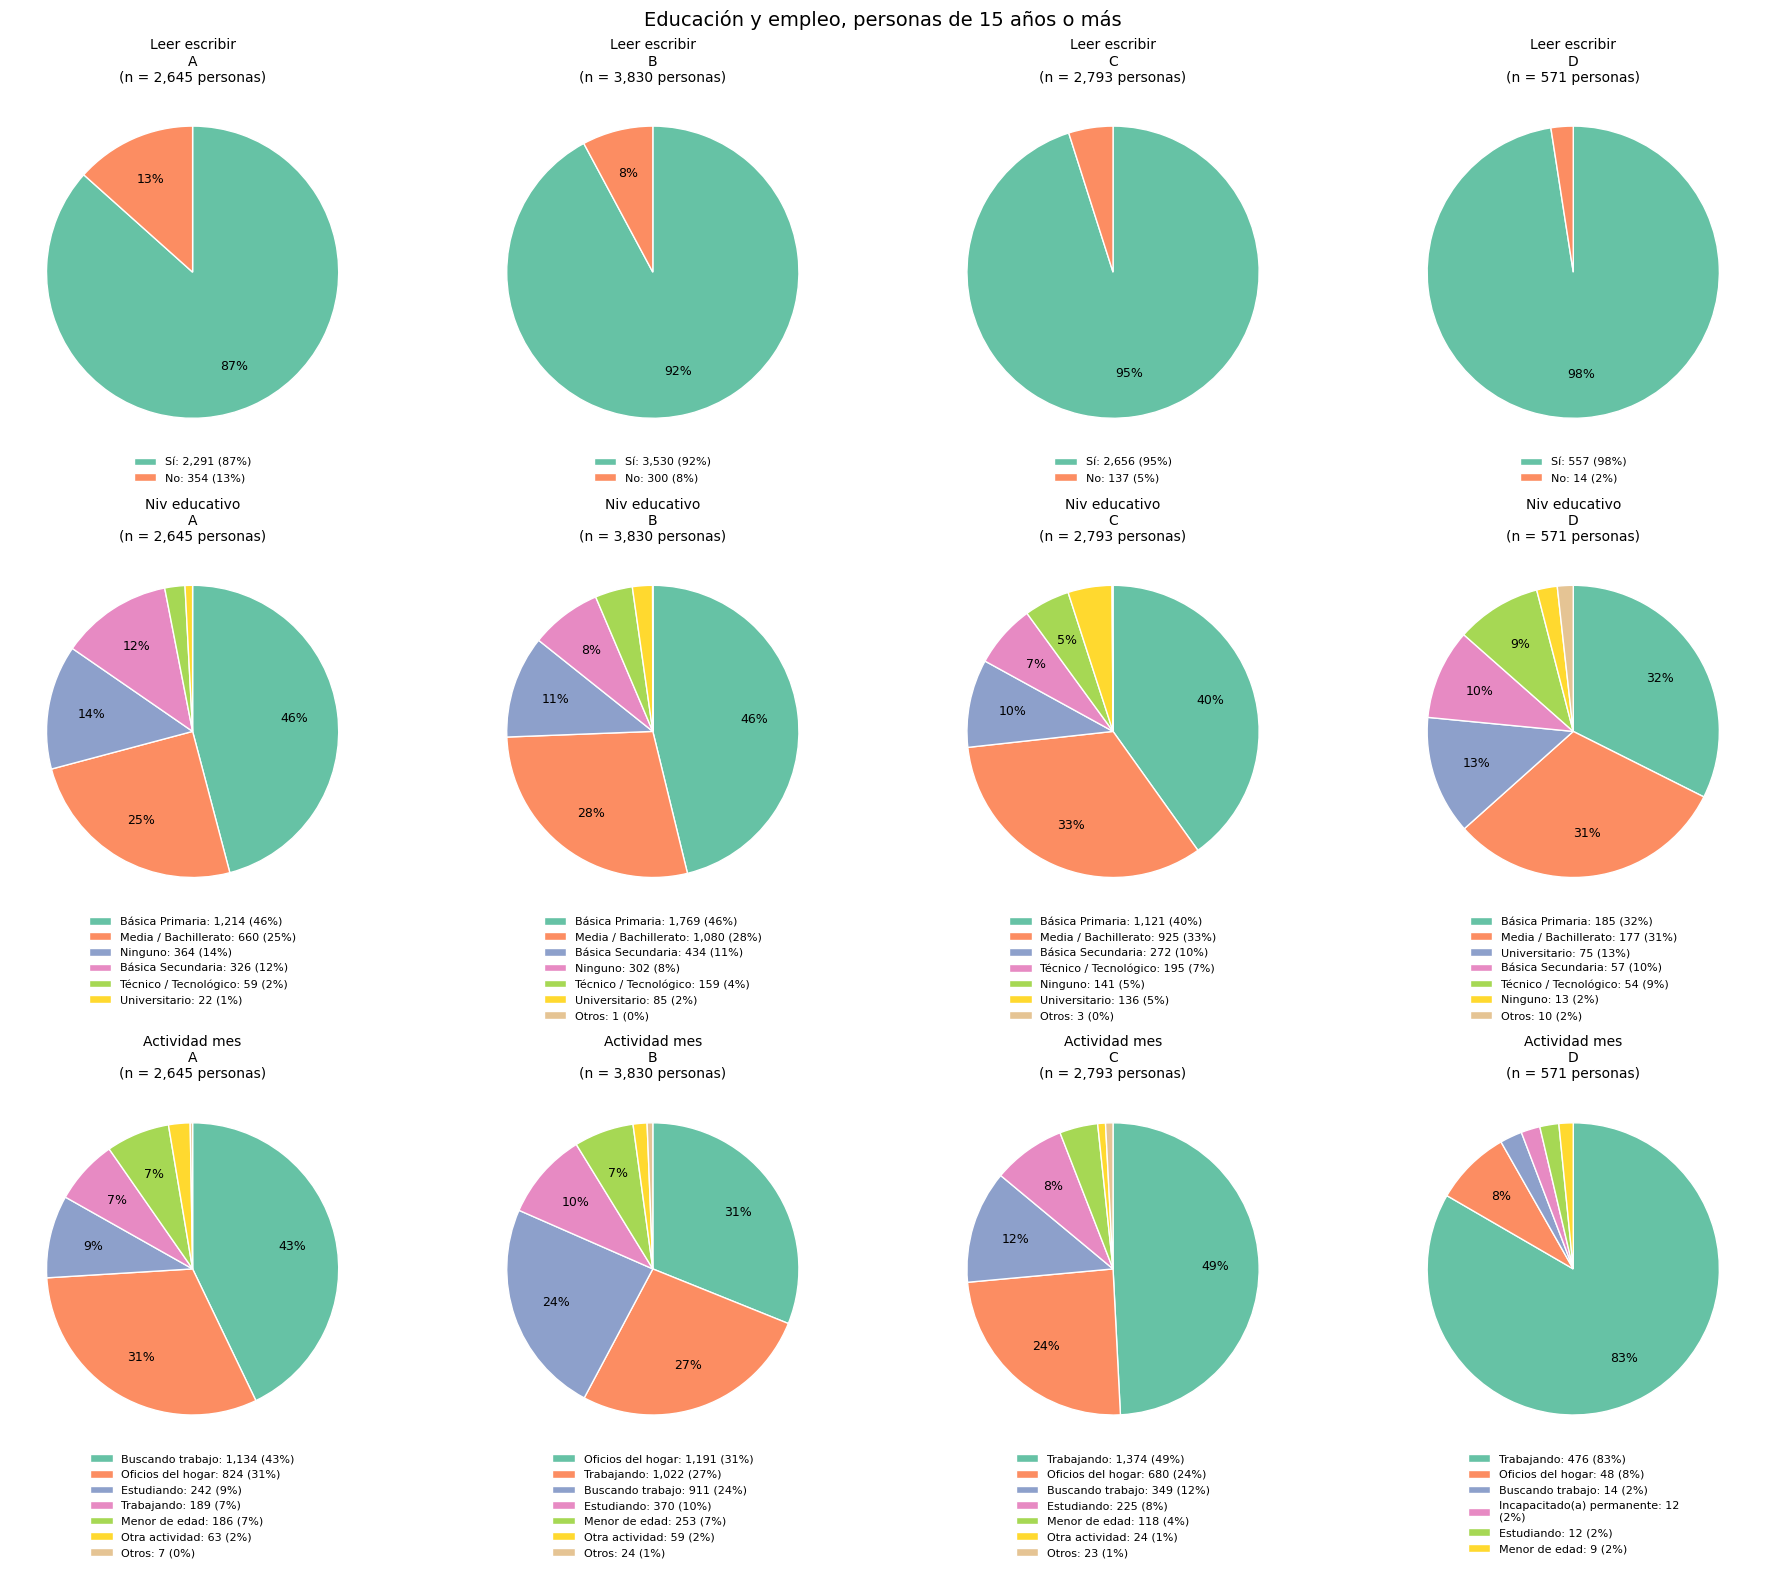

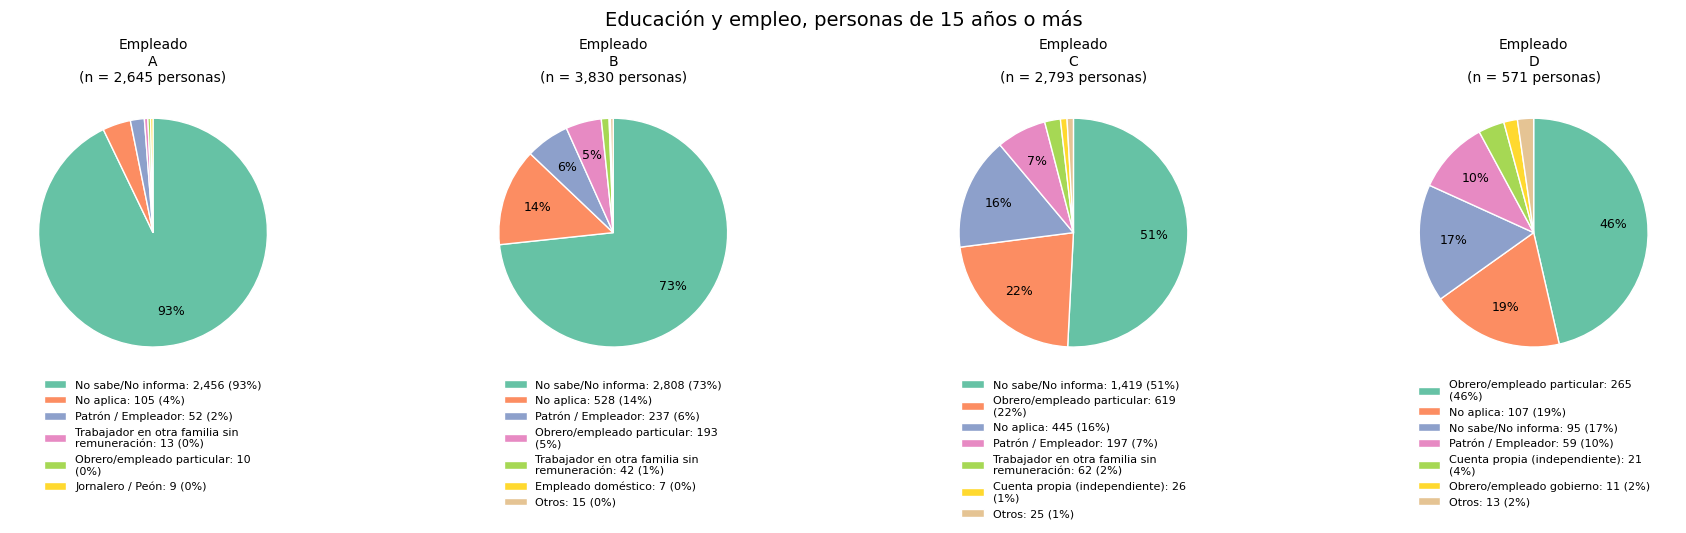

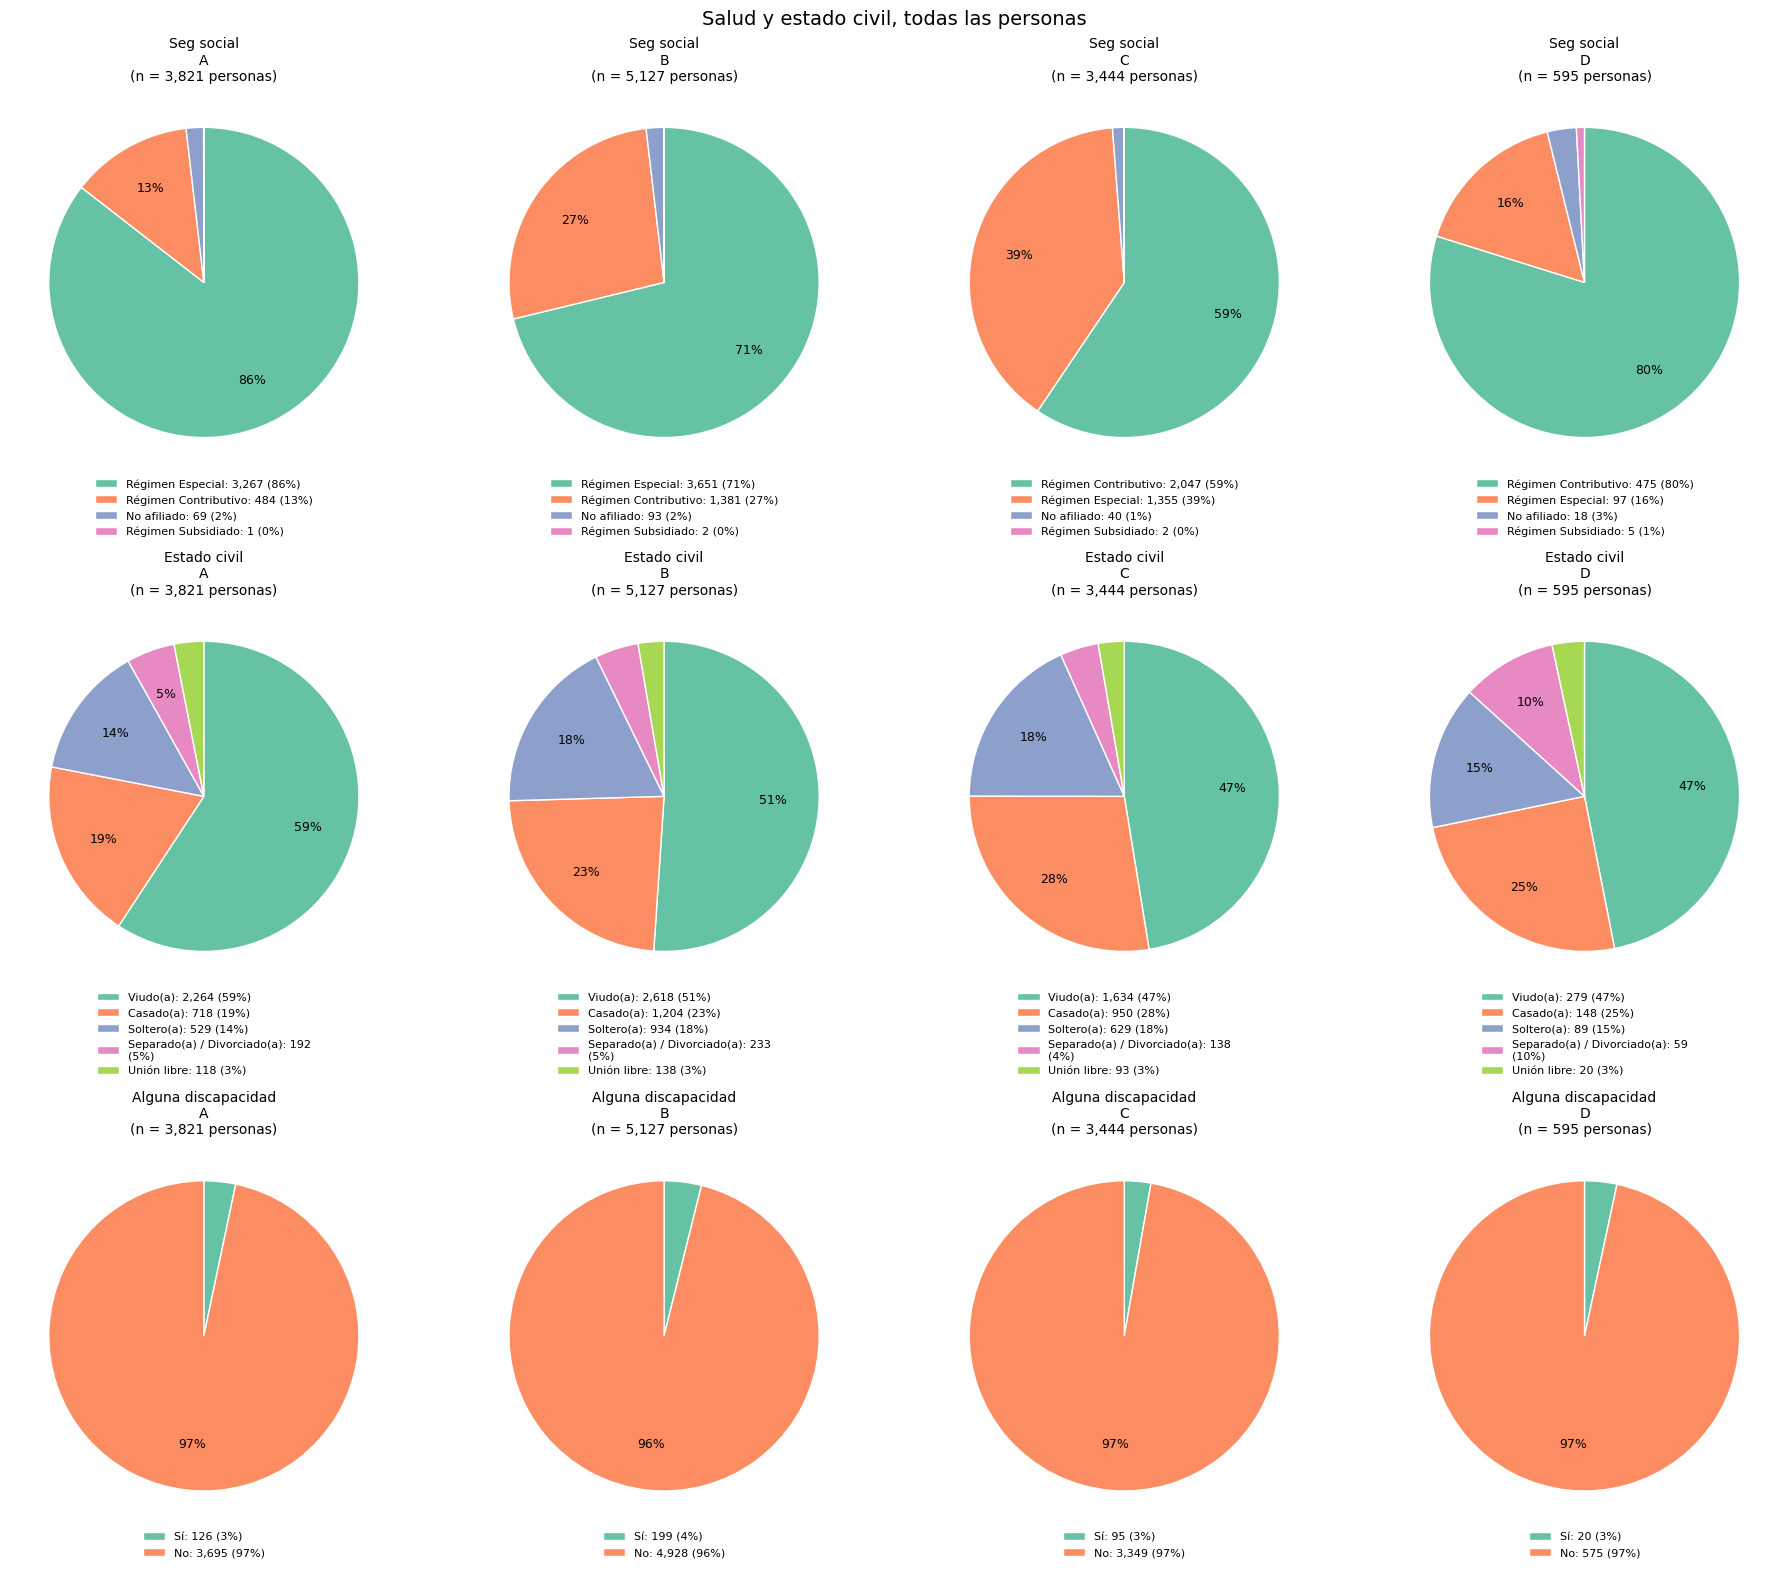

In [ ]:
if "ind_leer_escribir" in df_limpio.columns:
    print("\n% de analfabetismo (15+ años):")
    print(pct(mayores15["ind_leer_escribir"] == 0, mayores15["grupo"]).round(1))
tortas_por_vereda(mayores15, existentes(["ind_leer_escribir", "niv_educativo", "tip_actividad_mes", "tip_empleado"]),
                  "Educación y empleo, personas de 15 años o más")
tortas_por_vereda(df_limpio, existentes(["tip_seg_social", "tip_estado_civil", "alguna_discapacidad"]),
                  "Salud y estado civil, todas las personas")



=== INGRESOS Y GASTOS DEL HOGAR (COP/mes) ===
grupo                           A         B         C         D
ingreso_hogar    mean     89097.0  236983.0  328586.0  520113.0
                 median       0.0   90000.0  150000.0  200000.0
                 std     198333.0  310684.0  470723.0  739247.0
ingreso_pc       mean     23820.0   68808.0  127551.0  364479.0
                 median       0.0   33333.0   55000.0  150000.0
                 std      48384.0   89049.0  242545.0  532521.0
vlr_total_gastos mean    435952.0  492228.0  544569.0  555591.0
                 median  350000.0  420000.0  450000.0  380000.0
                 std     332006.0  364847.0  388136.0  512557.0
gasto_pc         mean    148184.0  185065.0  217455.0  403816.0
                 median  117500.0  151000.0  166667.0  290000.0
                 std     110539.0  147644.0  192016.0  398097.0


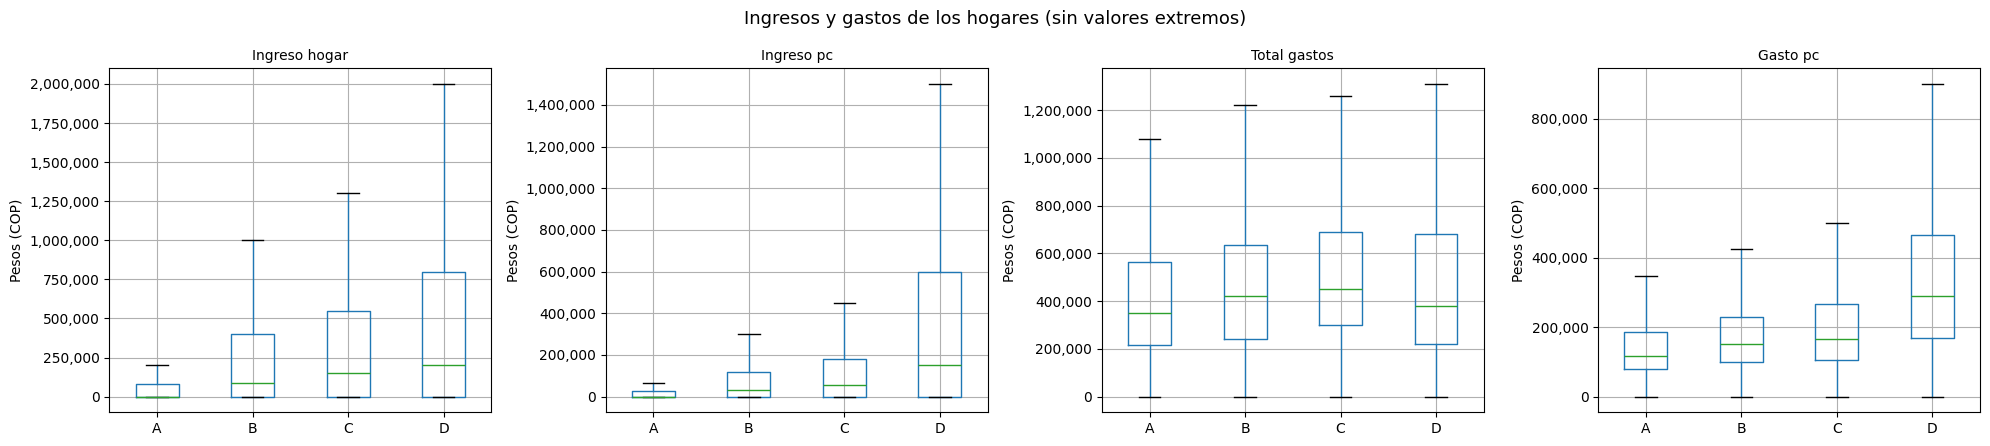

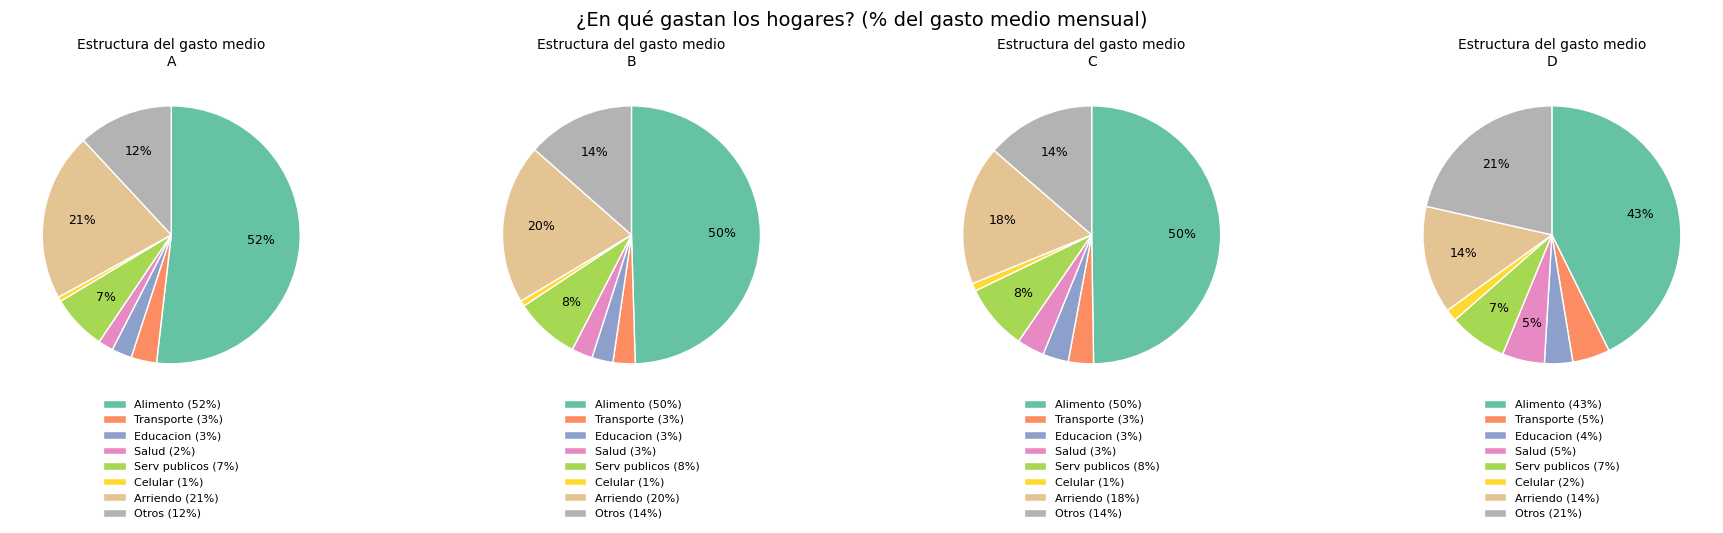

In [ ]:
vars_eco = existentes(["ingreso_hogar", "ingreso_pc", "vlr_total_gastos", "gasto_pc"])
print("\n=== INGRESOS Y GASTOS DEL HOGAR (COP/mes) ===")
print(hogares.groupby("grupo")[vars_eco].agg(["mean", "median", "std"]).round(0).T)

fig, axes = plt.subplots(1, len(vars_eco), figsize=(5 * len(vars_eco), 4.5), squeeze=False)
for ax, v in zip(axes[0], vars_eco):
    hogares.boxplot(column=v, by="grupo", showfliers=False, ax=ax)
    ax.set_title(nombre(v), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Pesos (COP)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.suptitle("Ingresos y gastos de los hogares (sin valores extremos)", fontsize=13)
plt.tight_layout()
plt.show()

medias = hogares.groupby("grupo")[VLR_GASTOS].mean()
medias.columns = [c.replace("vlr_gasto_", "").replace("_", " ").capitalize() for c in medias.columns]
tortas([medias.loc[v] for v in VER], [f"Estructura del gasto medio\n{v}" for v in VER], ncols=len(VER),
       suptitulo="¿En qué gastan los hogares? (% del gasto medio mensual)", con_n=False)


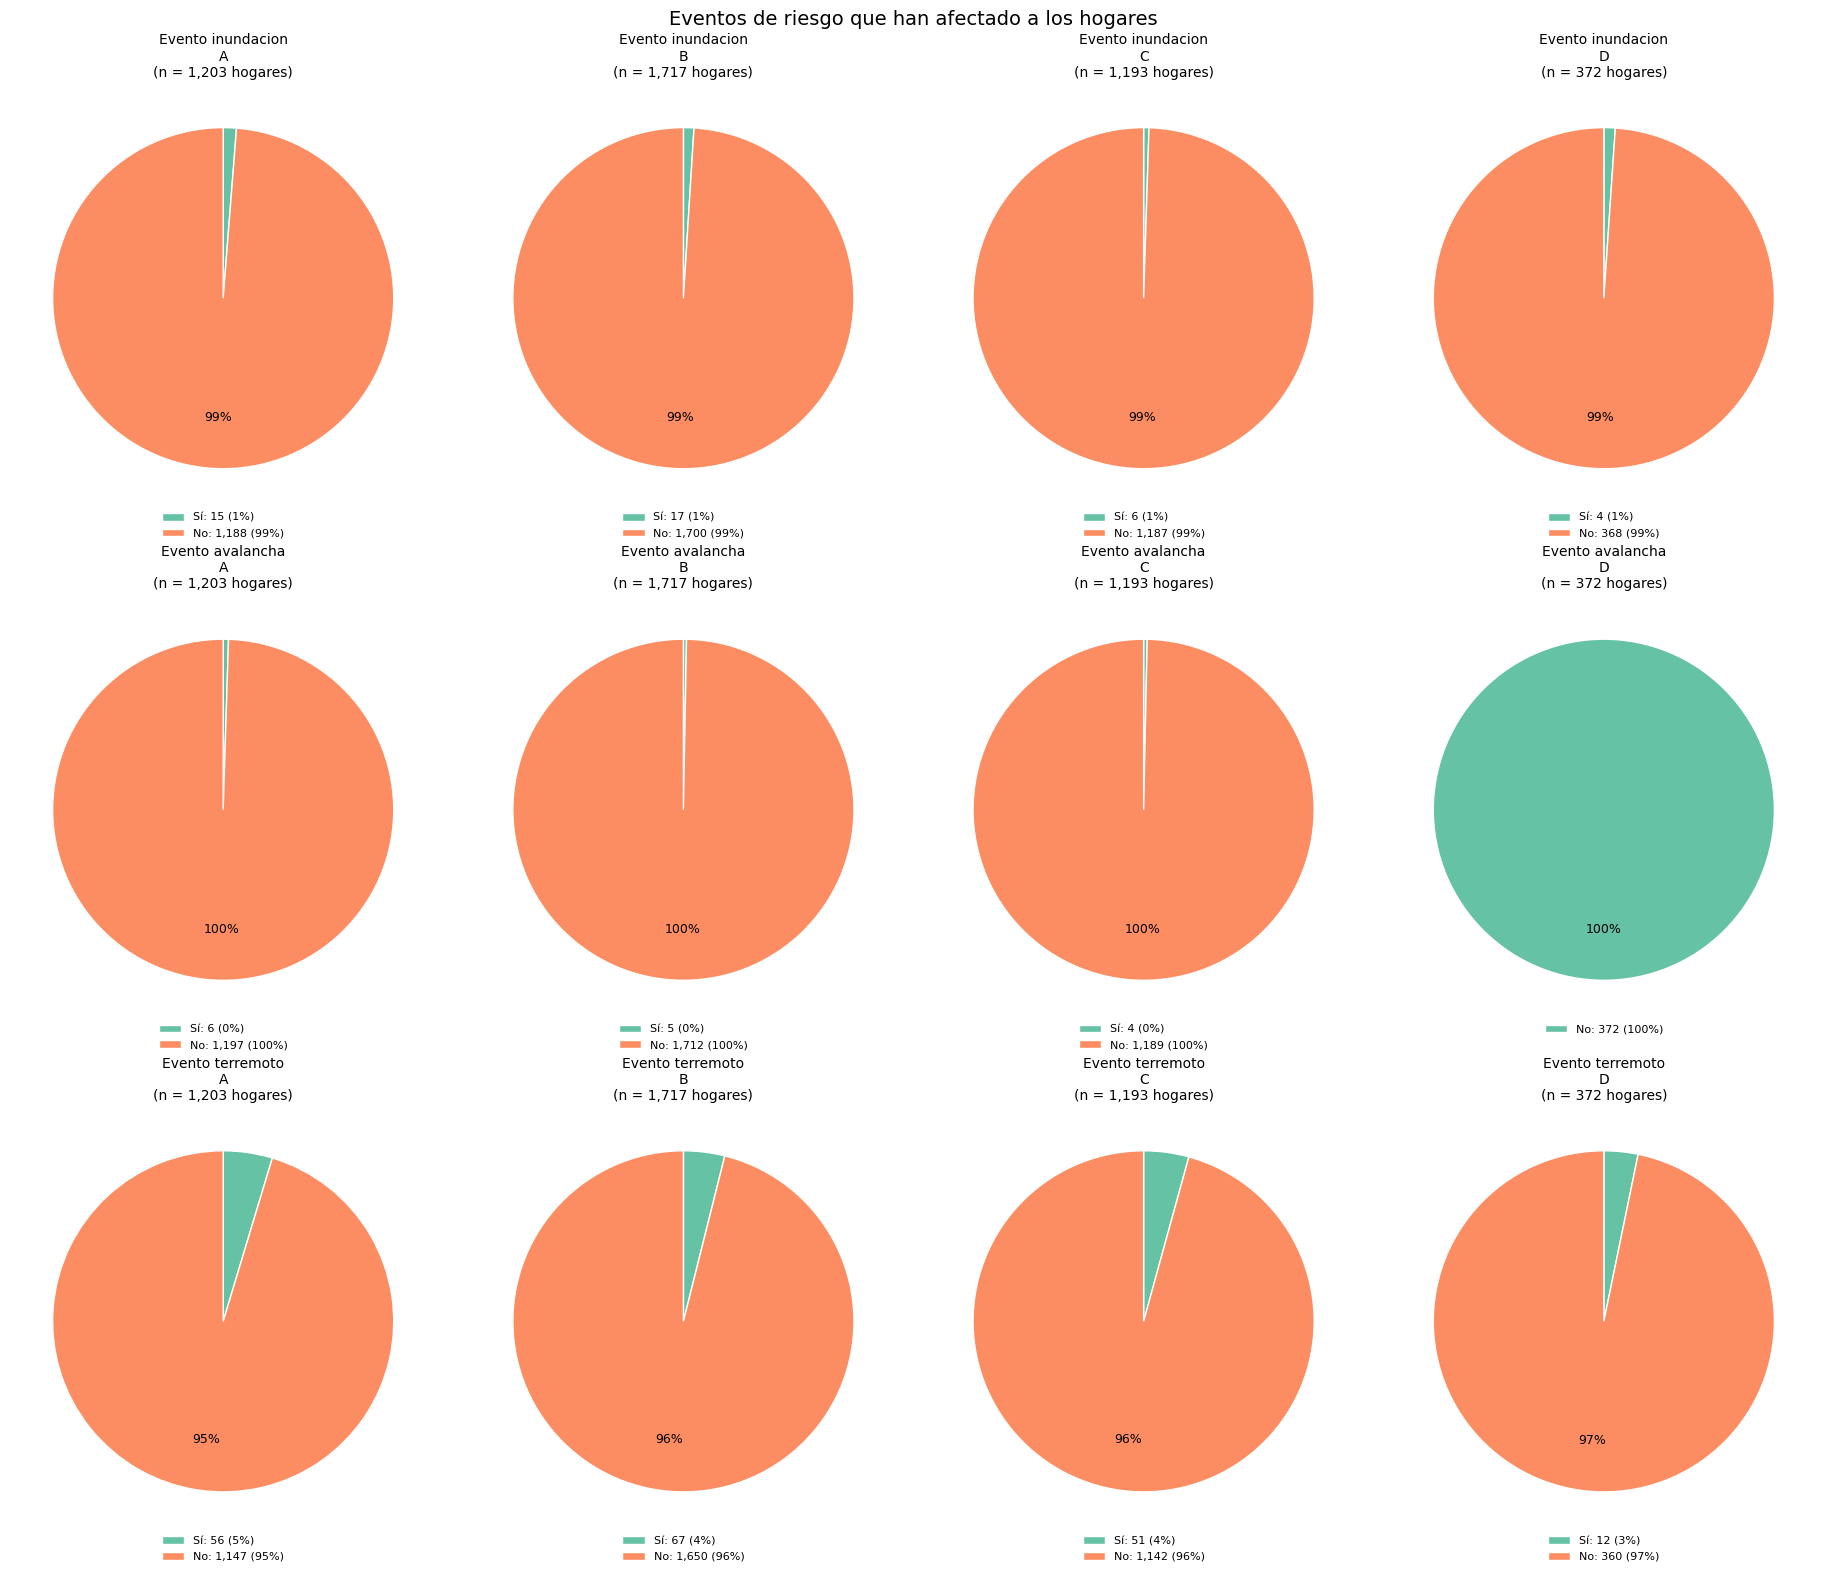

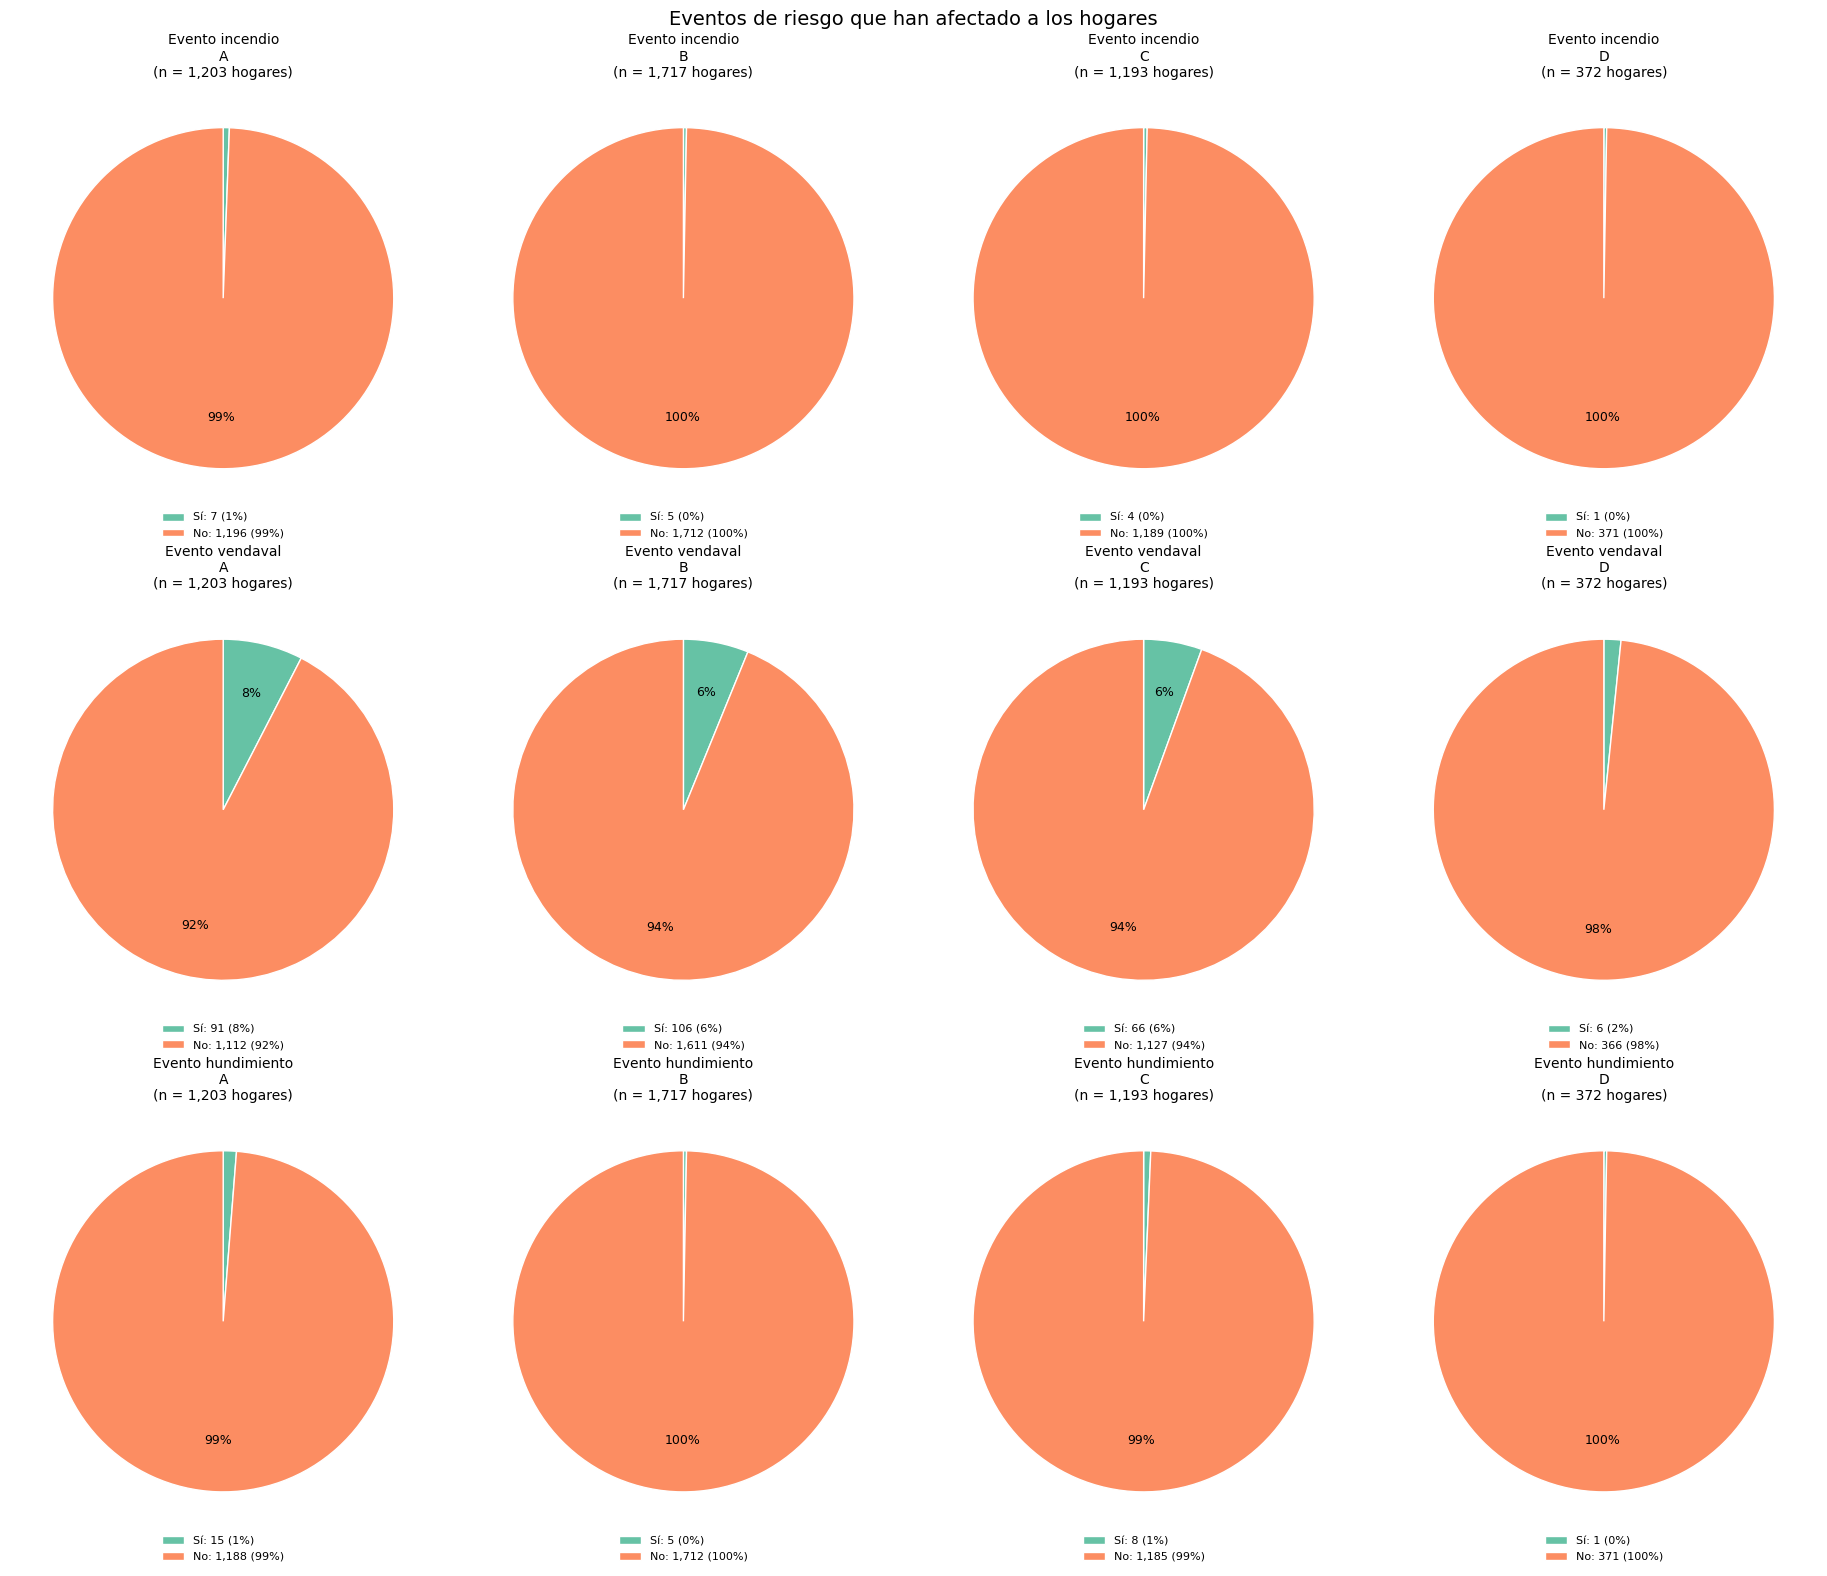

In [ ]:
tortas_por_vereda(hogares, existentes(["ind_evento_inundacion", "ind_evento_avalancha", "ind_evento_terremoto",
                                       "ind_evento_incendio", "ind_evento_vendaval", "ind_evento_hundimiento"]),
                  "Eventos de riesgo que han afectado a los hogares", unidad="hogares")


In [ ]:
pd.set_option("display.max_columns", None)       # para ver todas las columnas de la muestra
df_limpio.sample(min(15, len(df_limpio)))

,cod_dpto,departamento,cod_mpio,municipio,fec_paquete,num_paquete,num_ficha,ide_ficha_origen,ide_edificacion,ver_estructura,ori_encuesta,cod_clase,cod_centro_poblado,cod_area_coordinacion,cod_area_operativa,cod_uni_cobertura,cod_comuna,cod_corregimiento,nom_corregimiento,cod_vereda,nom_vereda,cod_barrio,nom_barrio,cod_enumerador,tot_viviendas,tot_hogares,ord_vivienda,ind_direccion,dir_vivienda,uso_vivienda,ide_foto,fec_ini_encuesta,fec_fin_encuesta,coord_x_manual_rec,coord_y_manual_rec,coord_x_auto_rec,coord_y_auto_rec,gps_alt_auto_rec,fec_captura_gps_rec,gps_distancia_rec,coord_x_manual_enc,coord_y_manual_enc,coord_x_auto_enc,coord_y_auto_enc,gps_alt_auto_enc,fec_captura_gps_enc,gps_distancia_enc,est_nov_cartografia,cod_digitador,fec_digitacion,ind_formato,num_hogares_recuento,est_ficha,cod_equipo_encuesta,num_visita,cod_chip,dir_chip,num_solicitud,cod_uc_total,tip_vivienda,tip_mat_paredes,tip_mat_pisos,ind_tiene_energia,tip_estrato_energia,ind_tiene_alcantarillado,ind_tiene_gas,ind_tiene_recoleccion,ind_tiene_acueducto,tip_estrato_acueducto,num_cuartos_vivienda,num_hogares_vivienda,cod_encuestador,cod_supervisor,cod_critico,fec_ini_vivienda,fec_fin_vivienda,ide_hogar,tip_ocupa_vivienda,num_cuartos_exclusivos,num_cuartos_dormir,num_cuartos_unicos_dormir,tip_sanitario,tip_ubi_sanitario,tip_uso_sanitario,tip_origen_agua,ind_agua_llega_7dias,num_dias_llega,ind_agua_llega_24horas,num_horas_llega,tip_uso_agua_beber,tip_elimina_basura,ind_tiene_cocina,tip_prepara_alimentos,tip_uso_cocina,tip_energia_cocina,ind_tiene_nevera,ind_tiene_lavadora,ind_tiene_pc,ind_tiene_internet,ind_tiene_moto,ind_tiene_tractor,ind_tiene_carro,ind_tiene_bien_raiz,ind_gasto_alimento,vlr_gasto_alimento,ind_gasto_transporte,vlr_gasto_transporte,ind_gasto_educacion,vlr_gasto_educacion,ind_gasto_salud,vlr_gasto_salud,ind_gasto_serv_publicos,vlr_gasto_serv_publicos,ind_gasto_celular,vlr_gasto_celular,ind_gasto_arriendo,vlr_gasto_arriendo,ind_gasto_otros,vlr_gasto_otros,vlr_total_gastos,num_habita_vivienda,ind_evento_inundacion,num_evento_inundacion,ind_evento_avalancha,num_evento_avalancha,ind_evento_terremoto,num_evento_terremoto,ind_evento_incendio,num_evento_incendio,ind_evento_vendaval,num_evento_vendaval,ind_evento_hundimiento,num_evento_hundimiento,num_personas_posibles,num_personas_hogar,fec_ini_visita1,fec_fin_visita1,res_visita1,fec_ini_visita2,fec_fin_visita2,res_visita2,ide_informante,pri_nom_informante,seg_nom_informante,pri_ape_informante,seg_ape_informante,tip_informante,ide_firma_informante,cau_sin_firma,email_contacto,num_tel_contacto,ind_declaracion,ide_persona,ide_nacional,ind_escaner,pri_apellido,seg_apellido,pri_nombre,seg_nombre,sexo_persona,ori_persona,tip_documento,num_documento,fec_nacimiento,edad_calculada,cod_dpto_documento,cod_mpio_documento,cod_pais_documento,tip_parentesco,tip_estado_civil,ind_conyuge_vive_hogar,ide_conyuge,ind_padre_vive_hogar,ide_padre,ind_pariente_domestico,ide_serv_domestico,ind_discap_ver,ind_discap_oir,ind_discap_hablar,ind_discap_moverse,ind_discap_bañarse,ind_discap_salir,ind_discap_entender,ind_discap_ninguna,tip_seg_social,ind_enfermo_30,ind_acudio_salud,ind_fue_atendido_salud,ind_esta_embarazada,ind_tuvo_hijos,tip_cuidado_niños,ind_recibe_comida,ind_leer_escribir,ind_estudia,niv_educativo,grado_alcanzado,ind_fondo_pensiones,tip_actividad_mes,num_sem_buscando,tip_empleado,ind_ingr_salario,vlr_ingr_salario,ind_ingr_honorarios,vlr_ingr_honorarios,ind_ingr_cosecha,num_mes_ingr_cosecha,vlr_ingr_cosecha,ind_ingr_pension,vlr_ingr_pension,ind_ingr_remesa_pais,vlr_ingr_remesa_pais,ind_ingr_remesa_exterior,vlr_ingr_remesa_exterior,ind_ingr_arriendos,vlr_ingr_arriendos,ind_otros_ingresos,vlr_otros_ingresos,ind_ingr_estado,vlr_ingr_fam_accion,vlr_ingr_col_mayor,vlr_ingr_otro_subsidio,fec_ini_persona1,fec_fin_persona1,fec_ini_persona2,fec_fin_persona2,ide_unigasto,jefe_ug,h_5,i1,i2,i3,i4,i5,i6,i7,i8,i9,i10,i11,i12,i13,i14,i15,grupo,nivel,ide_ug,persug,capital,marca,estado,linea_p,replicacion,fec_actualizacion_cns,c,c